In [1]:
#import torch
import pandas as pd
import os
import numpy as np
from tensorflow import keras
from tqdm import tqdm
import tensorflow as tf
from tensorflow.keras.models import Model
from tensorflow.keras.layers import Dense, Softmax, Dropout
from sklearn.model_selection import train_test_split
import matplotlib.pyplot as plt
from tensorflow.keras.wrappers.scikit_learn import KerasClassifier
from sklearn.model_selection import cross_val_score, StratifiedKFold
from sklearn.utils.class_weight import compute_class_weight
from sklearn.model_selection import train_test_split
from classification_models_1D.tfkeras import Classifiers

#device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
#print(device)

In [2]:
import os
os.environ['TF_CPP_MIN_LOG_LEVEL'] = '1'
os.environ['TF_FORCE_GPU_ALLOW_GROWTH'] = 'true'
os.environ['CUDA_VISIBLE_DEVICES']='1'
os.environ['WANDB_WATCH'] = 'false'
tensorflow_version = float(tf.__version__[0:3])
import wandb
# Get the GPU memory fraction to allocate
gpu_memory_fraction = 0.8
#pip install pyarrow fastparquet

In [3]:
#data = pd.read_parquet("/media/data1/ravram/DeepECG/ekg_waveforms_output/df_xml_2023_05_09_2004-to-june-2022_n_1572280_with_labelbox_no_duplicates.parquet")
data = pd.read_parquet("/media/data1/muse_ge/ECG_ad202207_1453937_cat_labels_original_diagnosis_v1.1.parquet")

In [4]:
import pandas as pd
from sklearn.model_selection import train_test_split
from tqdm import tqdm
#from iterstrat.ml_stratifiers import MultilabelStratifiedShuffleSplit
from sklearn.utils import indexable, _safe_indexing
from sklearn.utils.validation import _num_samples
from sklearn.model_selection._split import _validate_shuffle_split


csv_path = "NICM__Data.csv"
NICM_DATA = pd.read_csv(csv_path)

pd.set_option('display.max_columns', None)
# Load the XLSX file)
print(NICM_DATA.shape)
NICM_DATA.head()

(372, 51)


,Unnamed: 0,Correspondance dossier 2,CMD,CMPNI,DOB,Cas index,HTA,DM,IRC,NYHA,AF_msc,age_afmsc,FA,TVNS,date_ECG_NICM,QRS_dur,QRS_bb,Bbloq,ARNI,ACEouARA,ARM,ISGLT-2,Diuretique,Sex,Mutation,Gene,Amino Acid,DNA Change,DateFirstFU,Date_FirstMRI,CMR01,CMR_LVEF,CMR_LGE,LV_LGE,RVEF,HolterDx,MaxHolterPVCcountDx,DateHolterDx,ICD,Date_ICDimplantation,LTVAafterDx,DateLTVAafterDx,LTVAafterDx_CL,SevereLTVAafterDx,DateSevereLTVAafterDx,SevereLTVAafterDx_CL,DateLFU,DurationFU,AgeatDx,LTVA01,MRN
0,0,NICM1,CMD,yes,1990-07-01 00:00:00,1,0,0,0,2,0,NaN,0,0.0,2018-05-07 00:00:00,92,0,1.0,1.0,0.0,0.0,0.0,0.0,1,0.0,TPM1,p.Lys259Glu,c.775A>G,2018-09-12,2018-07-01 00:00:00,1,44.0,1,0.0,38.0,1.0,1,2018-11-13 00:00:00,0,NaN,0,NaN,NaN,0.0,NaN,NaN,2023-07-21,5.208219,28.219178,0,544960
1,1,NICM2,CMD,yes,1970-10-14 00:00:00,1,1,0,0,1,0,NaN,0,0.0,2018-07-05 00:00:00,106,0,1.0,1.0,0.0,0.0,0.0,0.0,1,1.0,MYBPC3 + TTN,p.Glu334Lys,c.1000G>A,2015-07-05,2017-01-12 00:00:00,1,43.0,1,1.0,59.0,0.0,NaN,NaN,0,NaN,0,NaN,NaN,0.0,NaN,NaN,2023-08-16,5.117808,44.753425,0,536354
2,2,NICM3,CMD,yes,1975-10-03 00:00:00,1,0,0,0,1,0,NaN,0,1.0,2012-12-07 00:00:00,82,0,1.0,1.0,0.0,0.0,0.0,0.0,1,0.0,NaN,NaN,NaN,2012-11-01,2012-12-10 00:00:00,1,29.0,1,0.0,36.0,0.0,NaN,NaN,1,2021-01-12 00:00:00,0,NaN,NaN,0.0,NaN,NaN,2024-03-19,11.287671,37.106849,0,463109
3,3,NICM4,CMD,yes,1955-10-21 00:00:00,1,1,0,0,1,0,NaN,3,1.0,2021-06-01 00:00:00,90,0,1.0,0.0,1.0,0.0,0.0,0.0,1,0.0,LMNA,p.(Arg72His),c.215G>A,2021-06-18,2021-06-25 00:00:00,1,34.0,1,1.0,41.0,1.0,2254,2023-01-06 00:00:00,1,2021-07-09 00:00:00,0,NaN,NaN,0.0,NaN,NaN,2023-01-19,1.635616,65.704110,0,591660
4,4,NICM5,CMD,yes,1948-02-03 00:00:00,1,0,1,0,2,0,NaN,0,1.0,2020-08-19 00:00:00,82,0,1.0,0.0,1.0,0.0,0.0,1.0,1,0.0,NaN,NaN,NaN,2020-06-01,2020-06-01 00:00:00,1,21.0,1,1.0,28.0,1.0,87,2021-07-16 00:00:00,0,NaN,0,NaN,NaN,0.0,NaN,NaN,2024-01-10,3.394521,72.375342,0,575300


In [5]:

csv_path = "/media/data1/mbahani/NICM_withCRTstatus.xlsx"
NICM_withCRT = pd.read_excel(csv_path)
pd.set_option('display.max_columns', None)
# Load the XLSX file)
print(NICM_withCRT.shape)
NICM_withCRT.head()
NICM_withCRT__ =  NICM_withCRT[[NICM_withCRT.columns[0],NICM_withCRT.columns[-1]]]
print(NICM_withCRT__.shape)

(431, 62)
(431, 2)


In [7]:
NICM_withCRT__.head()
NICM_DATA = pd.merge(NICM_DATA, NICM_withCRT__, left_on='Correspondance dossier 2', right_on='correspondance', how='left')

In [8]:
fam_ecg = NICM_DATA["MRN"].values.tolist()
fam_ecg = list(map(str,fam_ecg))
#data['RestingECG_PatientDemographics_PatientID'] = [str(i).replace("'","") for i in data['RestingECG_PatientDemographics_PatientID'].tolist()]
#data['RestingECG_PatientDemographics_PatientID'] = [str(i).zfill(7) for i in data['RestingECG_PatientDemographics_PatientID'].tolist()]
#data['RestingECG_PatientDemographics_PatientID'] = data['RestingECG_PatientDemographics_PatientID'].str.strip()

fam_ecg = [x.zfill(7) for x in fam_ecg]

# Now try creating the subset
data_ = data.loc[data['RestingECG_PatientDemographics_PatientID'].isin(fam_ecg)]
data_.shape


(4677, 583)

In [9]:
import pickle
#with open('NICM_Test_ids_list.pkl', 'wb') as f:pickle.dump(ids_test, f) #ids_test.append("0315104")ids_test.append("0320362")
with open('NICM_Test_ids_list.pkl', 'rb') as file:
    ids_test = pickle.load(file)

ids_test = [str(x).zfill(7) for x in ids_test[:-2]]

test_data_ = data_.loc[data_['RestingECG_PatientDemographics_PatientID'].isin(ids_test)]

train_data_ = data_.loc[~data_['RestingECG_PatientDemographics_PatientID'].isin(ids_test)]



In [ ]:
train_label = []
test_label = []

Train_feature = []

Test_feature = []
sub_set_ID = train_data_["RestingECG_PatientDemographics_PatientID"].values.tolist()
for patient_ID in  sub_set_ID:
    Train_feature.append(NICM_DATA.loc[NICM_DATA['MRN'] == int(patient_ID), :].values.flatten())

sub_set_ID = test_data_["RestingECG_PatientDemographics_PatientID"].values.tolist()
for patient_ID in  sub_set_ID:
    Test_feature.append(NICM_DATA.loc[NICM_DATA['MRN'] == int(patient_ID), :].values.flatten())
Train_feature = pd.DataFrame(Train_feature, columns=NICM_DATA.columns)
Test_feature = pd.DataFrame(Test_feature, columns=NICM_DATA.columns)


train_CV = Train_feature
print(train_CV.shape)
train_CV.head()
train_label = train_CV["LTVA01"].values.tolist()
test_label = Test_feature["LTVA01"].values.tolist()

In [11]:
from sklearn.preprocessing import MinMaxScaler
scaler = MinMaxScaler()

test_cv = Test_feature 

training_file_path = train_data_["npy_path"].values.tolist()
test_images_path = test_data_["npy_path"].values.tolist()


train_CV["npy_path"] = training_file_path 
test_cv["npy_path"] = test_images_path

train_CV["Age"] = train_data_["RestingECG_PatientDemographics_PatientAge"].values.tolist()
test_cv["Age"] = test_data_["RestingECG_PatientDemographics_PatientAge"].values.tolist()
train_CV['Age'] = scaler.fit_transform(train_CV[['Age']])
test_cv['Age'] = scaler.fit_transform(test_cv[['Age']])

train_CV.shape

(3874, 55)

In [13]:
test_cv["RestingECG_TestDemographics_AcquisitionDate"] = [str(j) for j in test_data_["RestingECG_TestDemographics_AcquisitionDate"]]
test_cv["RestingECG_TestDemographics_AcquisitionDate"] =  [str(i).replace("00:00:00","") for i in test_cv["RestingECG_TestDemographics_AcquisitionDate"].values.tolist()]
#test_cv['RestingECG_TestDemographics_AcquisitionDate'] = pd.to_datetime(test_cv['RestingECG_TestDemographics_AcquisitionDate'],format='mixed')
test_cv['RestingECG_TestDemographics_AcquisitionDate'] = (
    pd.to_datetime(test_cv['RestingECG_TestDemographics_AcquisitionDate'].str.strip(), errors="coerce")
)
test_cv["date_ECG_NICM"] = [str(j).replace("00:00:00","").replace("//","/").replace("/","-") for j in test_cv["date_ECG_NICM"]]
test_cv['date_ECG_NICM'] = pd.to_datetime(test_cv['date_ECG_NICM'],format='mixed')

train_CV["RestingECG_TestDemographics_AcquisitionDate"] = [str(j) for j in train_data_["RestingECG_TestDemographics_AcquisitionDate"]]
train_CV["RestingECG_TestDemographics_AcquisitionDate"] =  [str(i).replace("00:00:00","") for i in train_CV["RestingECG_TestDemographics_AcquisitionDate"].values.tolist()]
train_CV['RestingECG_TestDemographics_AcquisitionDate'] = pd.to_datetime(train_CV['RestingECG_TestDemographics_AcquisitionDate'],format='mixed')
train_CV["date_ECG_NICM"] = [str(j).replace("00:00:00","").replace("//","/").replace("/","-") for j in train_CV["date_ECG_NICM"]]
train_CV['date_ECG_NICM'] = pd.to_datetime(train_CV['date_ECG_NICM'],format='mixed')
train_CV.head()

,Unnamed: 0,Correspondance dossier 2,CMD,CMPNI,DOB,Cas index,HTA,DM,IRC,NYHA,AF_msc,age_afmsc,FA,TVNS,date_ECG_NICM,QRS_dur,QRS_bb,Bbloq,ARNI,ACEouARA,ARM,ISGLT-2,Diuretique,Sex,Mutation,Gene,Amino Acid,DNA Change,DateFirstFU,Date_FirstMRI,CMR01,CMR_LVEF,CMR_LGE,LV_LGE,RVEF,HolterDx,MaxHolterPVCcountDx,DateHolterDx,ICD,Date_ICDimplantation,LTVAafterDx,DateLTVAafterDx,LTVAafterDx_CL,SevereLTVAafterDx,DateSevereLTVAafterDx,SevereLTVAafterDx_CL,DateLFU,DurationFU,AgeatDx,LTVA01,MRN,correspondance,date_crt,npy_path,Age,RestingECG_TestDemographics_AcquisitionDate
0,139,NICM157,CMD,yes,1946-07-26 00:00:00,1,0,0,0,2,0,NaN,0,0.0,2015-09-26,144,1,1.0,0.0,0.0,0.0,0.0,0.0,0,0.0,NaN,NaN,NaN,1989-09-14,2019-09-30 00:00:00,1,36.0,1,0.0,56.0,0.0,NaN,NaN,0,NaN,0,NaN,NaN,0.0,NaN,NaN,2023-10-10,8.043836,43.167123,0,138467,NICM157,NaN,/media/data1/anolin/temp_new_dataset/ecg_npy/0...,0.870968,2017-12-21
1,139,NICM157,CMD,yes,1946-07-26 00:00:00,1,0,0,0,2,0,NaN,0,0.0,2015-09-26,144,1,1.0,0.0,0.0,0.0,0.0,0.0,0,0.0,NaN,NaN,NaN,1989-09-14,2019-09-30 00:00:00,1,36.0,1,0.0,56.0,0.0,NaN,NaN,0,NaN,0,NaN,NaN,0.0,NaN,NaN,2023-10-10,8.043836,43.167123,0,138467,NICM157,NaN,/media/data1/anolin/temp_new_dataset/ecg_npy/0...,0.870968,2017-12-20
2,139,NICM157,CMD,yes,1946-07-26 00:00:00,1,0,0,0,2,0,NaN,0,0.0,2015-09-26,144,1,1.0,0.0,0.0,0.0,0.0,0.0,0,0.0,NaN,NaN,NaN,1989-09-14,2019-09-30 00:00:00,1,36.0,1,0.0,56.0,0.0,NaN,NaN,0,NaN,0,NaN,NaN,0.0,NaN,NaN,2023-10-10,8.043836,43.167123,0,138467,NICM157,NaN,/media/data1/anolin/temp_new_dataset/ecg_npy/0...,0.870968,2017-12-20
3,139,NICM157,CMD,yes,1946-07-26 00:00:00,1,0,0,0,2,0,NaN,0,0.0,2015-09-26,144,1,1.0,0.0,0.0,0.0,0.0,0.0,0,0.0,NaN,NaN,NaN,1989-09-14,2019-09-30 00:00:00,1,36.0,1,0.0,56.0,0.0,NaN,NaN,0,NaN,0,NaN,NaN,0.0,NaN,NaN,2023-10-10,8.043836,43.167123,0,138467,NICM157,NaN,/media/data1/anolin/temp_new_dataset/ecg_npy/0...,0.661290,2004-12-14
4,139,NICM157,CMD,yes,1946-07-26 00:00:00,1,0,0,0,2,0,NaN,0,0.0,2015-09-26,144,1,1.0,0.0,0.0,0.0,0.0,0.0,0,0.0,NaN,NaN,NaN,1989-09-14,2019-09-30 00:00:00,1,36.0,1,0.0,56.0,0.0,NaN,NaN,0,NaN,0,NaN,NaN,0.0,NaN,NaN,2023-10-10,8.043836,43.167123,0,138467,NICM157,NaN,/media/data1/anolin/temp_new_dataset/ecg_npy/0...,0.935484,2021-12-01


In [14]:
import pandas as pd
from datetime import datetime
today_date = pd.to_datetime(datetime.now().date())

# Define a function to sort each group by the nearest date to today
def sort_by_nearest_date(group):
    return group.assign(
        distance_to_today=abs(group['RestingECG_TestDemographics_AcquisitionDate'] - today_date)
    ).sort_values(by='distance_to_today').drop(columns='distance_to_today')

# Sort each group by the nearest date to today using groupby and apply
sorted_df = test_cv.groupby('MRN', group_keys=False).apply(sort_by_nearest_date)

# Reset index after sorting
sorted_df.reset_index(drop=True, inplace=True)

In [16]:
import pandas as pd
import datetime

def convert_excel_date(excel_date):
    try:
        # Check if the value is a number (Excel date)
        temp = datetime.datetime(1899, 12, 30)  # Correct base date
        delta = datetime.timedelta(days=int(float(excel_date)))
        converted_date = temp + delta
        return converted_date.strftime("%Y-%m-%d")
    except (ValueError, TypeError):
        # If conversion fails, return the original value (assuming it's a string date)
        return excel_date

# Apply conversion function
sorted_df["DateLTVAafterDx"] = [convert_excel_date(j) if not pd.isnull(j) else j for j in sorted_df["DateLTVAafterDx"]]

# Convert all dates to datetime format
sorted_df["DateLTVAafterDx"] = pd.to_datetime(sorted_df["DateLTVAafterDx"], errors='coerce')

# Ensure all dates are in a consistent format
sorted_df["DateLTVAafterDx"] = sorted_df["DateLTVAafterDx"].dt.strftime("%Y-%m-%d")

# Convert back to datetime for date comparison
sorted_df["DateLTVAafterDx"] = pd.to_datetime(sorted_df["DateLTVAafterDx"], errors='coerce')



In [ ]:
import pandas as pd
import datetime
import numpy as np

def convert_excel_date(value):
    """
    Convert Excel numeric date to datetime.
    If the value is already a string date, return as-is.
    """
    if pd.isnull(value):
        return pd.NaT
    try:
        # If it's a number, treat as Excel date
        excel_float = float(value)
        base_date = datetime.datetime(1899, 12, 30)
        converted_date = base_date + datetime.timedelta(days=excel_float)
        return converted_date
    except (ValueError, TypeError):
        # If conversion fails, try parsing as string
        try:
            return pd.to_datetime(value, errors='coerce')
        except:
            return pd.NaT

# Apply conversion function
sorted_df["DateLTVAafterDx"] = sorted_df["DateLTVAafterDx"].apply(convert_excel_date)



In [18]:
import datetime
import pandas as pd

# Get today's date
today_date = pd.to_datetime(datetime.datetime.now().date())

# Define a function to calculate the absolute difference between each date and today's date
def nearest_to_today(row):
    date1 = row['RestingECG_TestDemographics_AcquisitionDate']
    date2 = row['DateLTVAafterDx']
    
    if pd.isnull(date1) and pd.isnull(date2):
        return False  # Both dates are missing, no meaningful comparison can be made
    elif pd.isnull(date1):
        return False  # 'RestingECG_TestDemographics_AcquisitionDate' is missing
    elif pd.isnull(date2):
        return True  # 'DateLTVAafterDx' is missing, consider it as nearest to today
    else:
        today_date = pd.Timestamp.now().normalize()
        return abs(date1 - today_date) > abs(date2 - today_date)

# Filter the DataFrame based on the nearest date to today
filtered_df = sorted_df[sorted_df.apply(nearest_to_today, axis=1)]

In [18]:
filtered_df[filtered_df["DateLTVAafterDx"]=="2016-01-07"].head()

,Unnamed: 0,Correspondance dossier 2,CMD,CMPNI,DOB,Cas index,HTA,DM,IRC,NYHA,AF_msc,age_afmsc,FA,TVNS,date_ECG_NICM,QRS_dur,QRS_bb,Bbloq,ARNI,ACEouARA,ARM,ISGLT-2,Diuretique,Sex,Mutation,Gene,Amino Acid,DNA Change,DateFirstFU,Date_FirstMRI,CMR01,CMR_LVEF,CMR_LGE,LV_LGE,RVEF,HolterDx,MaxHolterPVCcountDx,DateHolterDx,ICD,Date_ICDimplantation,LTVAafterDx,DateLTVAafterDx,LTVAafterDx_CL,SevereLTVAafterDx,DateSevereLTVAafterDx,SevereLTVAafterDx_CL,DateLFU,DurationFU,AgeatDx,LTVA01,MRN,correspondance,date_crt,npy_path,Age,RestingECG_TestDemographics_AcquisitionDate
104,369,NICM504,CMD,yes,1958-08-27 00:00:00,1,0,0,0,2,0,NaN,0,1.0,2005-02-13,116,0,1.0,0.0,1.0,1.0,0.0,1.0,1,0.0,NaN,NaN,NaN,1997-07-17,NaN,0,NaN,NaN,NaN,NaN,0.0,NaN,NaN,1,2005-07-13 00:00:00,2,2016-01-07,222bpm,0.0,NaN,NaN,2016-09-05,11.567123,38.915068,1,241068,NICM504,NaN,/media/data1/anolin/temp_new_dataset/ecg_npy/0...,0.66129,2015-12-23
105,369,NICM504,CMD,yes,1958-08-27 00:00:00,1,0,0,0,2,0,NaN,0,1.0,2005-02-13,116,0,1.0,0.0,1.0,1.0,0.0,1.0,1,0.0,NaN,NaN,NaN,1997-07-17,NaN,0,NaN,NaN,NaN,NaN,0.0,NaN,NaN,1,2005-07-13 00:00:00,2,2016-01-07,222bpm,0.0,NaN,NaN,2016-09-05,11.567123,38.915068,1,241068,NICM504,NaN,/media/data1/anolin/temp_new_dataset/ecg_npy/0...,0.66129,2015-12-12
106,369,NICM504,CMD,yes,1958-08-27 00:00:00,1,0,0,0,2,0,NaN,0,1.0,2005-02-13,116,0,1.0,0.0,1.0,1.0,0.0,1.0,1,0.0,NaN,NaN,NaN,1997-07-17,NaN,0,NaN,NaN,NaN,NaN,0.0,NaN,NaN,1,2005-07-13 00:00:00,2,2016-01-07,222bpm,0.0,NaN,NaN,2016-09-05,11.567123,38.915068,1,241068,NICM504,NaN,/media/data1/anolin/temp_new_dataset/ecg_npy/0...,0.66129,2015-12-11
107,369,NICM504,CMD,yes,1958-08-27 00:00:00,1,0,0,0,2,0,NaN,0,1.0,2005-02-13,116,0,1.0,0.0,1.0,1.0,0.0,1.0,1,0.0,NaN,NaN,NaN,1997-07-17,NaN,0,NaN,NaN,NaN,NaN,0.0,NaN,NaN,1,2005-07-13 00:00:00,2,2016-01-07,222bpm,0.0,NaN,NaN,2016-09-05,11.567123,38.915068,1,241068,NICM504,NaN,/media/data1/anolin/temp_new_dataset/ecg_npy/0...,0.66129,2015-12-10
108,369,NICM504,CMD,yes,1958-08-27 00:00:00,1,0,0,0,2,0,NaN,0,1.0,2005-02-13,116,0,1.0,0.0,1.0,1.0,0.0,1.0,1,0.0,NaN,NaN,NaN,1997-07-17,NaN,0,NaN,NaN,NaN,NaN,0.0,NaN,NaN,1,2005-07-13 00:00:00,2,2016-01-07,222bpm,0.0,NaN,NaN,2016-09-05,11.567123,38.915068,1,241068,NICM504,NaN,/media/data1/anolin/temp_new_dataset/ecg_npy/0...,0.66129,2015-11-27


In [20]:
import datetime
import pandas as pd

# Get today's date
today_date = pd.to_datetime(datetime.datetime.now().date())

# Define a function to calculate the absolute difference between each date and today's date
def nearest_to_today__(row):
    date1 = row['RestingECG_TestDemographics_AcquisitionDate']
    date2 = row['date_ECG_NICM']
    
    if pd.isnull(date1) and pd.isnull(date2):
        return False  # Both dates are missing, no meaningful comparison can be made
    elif pd.isnull(date1):
        return False  # 'RestingECG_TestDemographics_AcquisitionDate' is missing
    elif pd.isnull(date2):
        return True  # 'DateLTVAafterDx' is missing, consider it as nearest to today
    else:
        today_date = pd.Timestamp.now().normalize()
        return abs(date1 - today_date) < abs(date2 - today_date)

# Filter the DataFrame based on the nearest date to today
filtered_df = filtered_df[filtered_df.apply(nearest_to_today__, axis=1)]

In [21]:
filtered_df[filtered_df["DateLTVAafterDx"]=="2016-01-07"].head()

,Unnamed: 0,Correspondance dossier 2,CMD,CMPNI,DOB,Cas index,HTA,DM,IRC,NYHA,AF_msc,age_afmsc,FA,TVNS,date_ECG_NICM,QRS_dur,QRS_bb,Bbloq,ARNI,ACEouARA,ARM,ISGLT-2,Diuretique,Sex,Mutation,Gene,Amino Acid,DNA Change,DateFirstFU,Date_FirstMRI,CMR01,CMR_LVEF,CMR_LGE,LV_LGE,RVEF,HolterDx,MaxHolterPVCcountDx,DateHolterDx,ICD,Date_ICDimplantation,LTVAafterDx,DateLTVAafterDx,LTVAafterDx_CL,SevereLTVAafterDx,DateSevereLTVAafterDx,SevereLTVAafterDx_CL,DateLFU,DurationFU,AgeatDx,LTVA01,MRN,correspondance,date_crt,npy_path,Age,RestingECG_TestDemographics_AcquisitionDate
104,369,NICM504,CMD,yes,1958-08-27 00:00:00,1,0,0,0,2,0,NaN,0,1.0,2005-02-13,116,0,1.0,0.0,1.0,1.0,0.0,1.0,1,0.0,NaN,NaN,NaN,1997-07-17,NaN,0,NaN,NaN,NaN,NaN,0.0,NaN,NaN,1,2005-07-13 00:00:00,2,2016-01-07,222bpm,0.0,NaN,NaN,2016-09-05,11.567123,38.915068,1,241068,NICM504,NaN,/media/data1/anolin/temp_new_dataset/ecg_npy/0...,0.66129,2015-12-23
105,369,NICM504,CMD,yes,1958-08-27 00:00:00,1,0,0,0,2,0,NaN,0,1.0,2005-02-13,116,0,1.0,0.0,1.0,1.0,0.0,1.0,1,0.0,NaN,NaN,NaN,1997-07-17,NaN,0,NaN,NaN,NaN,NaN,0.0,NaN,NaN,1,2005-07-13 00:00:00,2,2016-01-07,222bpm,0.0,NaN,NaN,2016-09-05,11.567123,38.915068,1,241068,NICM504,NaN,/media/data1/anolin/temp_new_dataset/ecg_npy/0...,0.66129,2015-12-12
106,369,NICM504,CMD,yes,1958-08-27 00:00:00,1,0,0,0,2,0,NaN,0,1.0,2005-02-13,116,0,1.0,0.0,1.0,1.0,0.0,1.0,1,0.0,NaN,NaN,NaN,1997-07-17,NaN,0,NaN,NaN,NaN,NaN,0.0,NaN,NaN,1,2005-07-13 00:00:00,2,2016-01-07,222bpm,0.0,NaN,NaN,2016-09-05,11.567123,38.915068,1,241068,NICM504,NaN,/media/data1/anolin/temp_new_dataset/ecg_npy/0...,0.66129,2015-12-11
107,369,NICM504,CMD,yes,1958-08-27 00:00:00,1,0,0,0,2,0,NaN,0,1.0,2005-02-13,116,0,1.0,0.0,1.0,1.0,0.0,1.0,1,0.0,NaN,NaN,NaN,1997-07-17,NaN,0,NaN,NaN,NaN,NaN,0.0,NaN,NaN,1,2005-07-13 00:00:00,2,2016-01-07,222bpm,0.0,NaN,NaN,2016-09-05,11.567123,38.915068,1,241068,NICM504,NaN,/media/data1/anolin/temp_new_dataset/ecg_npy/0...,0.66129,2015-12-10
108,369,NICM504,CMD,yes,1958-08-27 00:00:00,1,0,0,0,2,0,NaN,0,1.0,2005-02-13,116,0,1.0,0.0,1.0,1.0,0.0,1.0,1,0.0,NaN,NaN,NaN,1997-07-17,NaN,0,NaN,NaN,NaN,NaN,0.0,NaN,NaN,1,2005-07-13 00:00:00,2,2016-01-07,222bpm,0.0,NaN,NaN,2016-09-05,11.567123,38.915068,1,241068,NICM504,NaN,/media/data1/anolin/temp_new_dataset/ecg_npy/0...,0.66129,2015-11-27


In [22]:
def nearest_to_today__(row):
    date1 = pd.to_datetime(row['RestingECG_TestDemographics_AcquisitionDate'], errors='coerce')
    date2 = pd.to_datetime(row['date_crt'], errors='coerce')
    
    if pd.isnull(date1) and pd.isnull(date2):
        return False  # Both dates are missing, no meaningful comparison can be made
    elif pd.isnull(date1):
        return False  # 'RestingECG_TestDemographics_AcquisitionDate' is missing
    elif pd.isnull(date2):
        return True  # 'DateLTVAafterDx' is missing, consider it as nearest to today
    else:
        today_date = pd.Timestamp.now().normalize()
        return abs(date1 - today_date) > abs(date2 - today_date)

# Filter the DataFrame based on the nearest date to today
filtered_df = filtered_df[filtered_df.apply(nearest_to_today__, axis=1)]

<ipython-input-22-3d489b251080>:3: UserWarning: Parsing dates in %d-%m-%Y format when dayfirst=False (the default) was specified. Pass `dayfirst=True` or specify a format to silence this warning.
  date2 = pd.to_datetime(row['date_crt'], errors='coerce')


In [23]:
filtered_df.shape

(422, 56)

In [24]:
filtered_df["date_crt"].value_counts()

date_crt
13-09-2016    6
21-02-2018    6
21-08-2019    5
24-11-2020    4
15-06-2016    3
06-12-2013    2
21-11-2017    1
Name: count, dtype: int64

In [26]:
filtered_df.shape

(422, 56)

In [64]:
test_cv = filtered_df

In [28]:
import pandas as pd
from datetime import datetime
today_date = pd.to_datetime(datetime.now().date())

# Define a function to sort each group by the nearest date to today
def sort_by_nearest_date(group):
    return group.assign(
        distance_to_today=abs(group['RestingECG_TestDemographics_AcquisitionDate'] - today_date)
    ).sort_values(by='distance_to_today').drop(columns='distance_to_today')

# Sort each group by the nearest date to today using groupby and apply
sorted_df = train_CV.groupby('MRN', group_keys=False).apply(sort_by_nearest_date)

# Reset index after sorting
sorted_df.reset_index(drop=True, inplace=True)

import pandas as pd
import datetime

def convert_excel_date(excel_date):
    try:
        # Check if the value is a number (Excel date)
        temp = datetime.datetime(1899, 12, 30)  # Correct base date
        delta = datetime.timedelta(days=int(float(excel_date)))
        converted_date = temp + delta
        return converted_date.strftime("%Y-%m-%d")
    except (ValueError, TypeError):
        # If conversion fails, return the original value (assuming it's a string date)
        return excel_date

# Apply conversion function
sorted_df["DateLTVAafterDx"] = [convert_excel_date(j) if not pd.isnull(j) else j for j in sorted_df["DateLTVAafterDx"]]

# Convert all dates to datetime format
sorted_df["DateLTVAafterDx"] = pd.to_datetime(sorted_df["DateLTVAafterDx"], errors='coerce')

# Ensure all dates are in a consistent format
sorted_df["DateLTVAafterDx"] = sorted_df["DateLTVAafterDx"].dt.strftime("%Y-%m-%d")

# Convert back to datetime for date comparison
sorted_df["DateLTVAafterDx"] = pd.to_datetime(sorted_df["DateLTVAafterDx"], errors='coerce')


import datetime
import pandas as pd

# Get today's date
today_date = pd.to_datetime(datetime.datetime.now().date())

# Define a function to calculate the absolute difference between each date and today's date
def nearest_to_today(row):
    date1 = row['RestingECG_TestDemographics_AcquisitionDate']
    date2 = row['DateLTVAafterDx']
    
    if pd.isnull(date1) and pd.isnull(date2):
        return False  # Both dates are missing, no meaningful comparison can be made
    elif pd.isnull(date1):
        return False  # 'RestingECG_TestDemographics_AcquisitionDate' is missing
    elif pd.isnull(date2):
        return True  # 'DateLTVAafterDx' is missing, consider it as nearest to today
    else:
        today_date = pd.Timestamp.now().normalize()
        return abs(date1 - today_date) > abs(date2 - today_date)

# Filter the DataFrame based on the nearest date to today
filtered_df = sorted_df[sorted_df.apply(nearest_to_today, axis=1)]

import datetime
import pandas as pd

# Get today's date
today_date = pd.to_datetime(datetime.datetime.now().date())

# Define a function to calculate the absolute difference between each date and today's date
def nearest_to_today__(row):
    date1 = row['RestingECG_TestDemographics_AcquisitionDate']
    date2 = row['date_ECG_NICM']
    
    if pd.isnull(date1) and pd.isnull(date2):
        return False  # Both dates are missing, no meaningful comparison can be made
    elif pd.isnull(date1):
        return False  # 'RestingECG_TestDemographics_AcquisitionDate' is missing
    elif pd.isnull(date2):
        return True  # 'DateLTVAafterDx' is missing, consider it as nearest to today
    else:
        today_date = pd.Timestamp.now().normalize()
        return abs(date1 - today_date) < abs(date2 - today_date)

# Filter the DataFrame based on the nearest date to today
filtered_df = filtered_df[filtered_df.apply(nearest_to_today__, axis=1)]


train_CV = filtered_df
train_CV.shape

(2637, 56)

In [26]:
import numpy as np
from tensorflow.keras.utils import Sequence

class DataGenerator(Sequence):
    def __init__(self, x_ecg, x_numerical, y_set, batch_size, shuffle=True):
        self.x_ecg, self.x_numerical, self.y = x_ecg, x_numerical, y_set
        self.batch_size = batch_size
        self.shuffle = shuffle
        self.indexes = np.arange(len(self.x_ecg))
        if self.shuffle:
            np.random.shuffle(self.indexes)

    def __len__(self):
        return int(np.ceil(len(self.x_ecg) / float(self.batch_size)))

    def __getitem__(self, idx):
        start_idx = idx * self.batch_size
        end_idx = (idx + 1) * self.batch_size

        batch_indices = self.indexes[start_idx:end_idx]
        batch_x_ecg = self.x_ecg[batch_indices].astype(np.float32)
        batch_x_numerical = self.x_numerical[batch_indices].astype(np.float32)
        batch_y = self.y[batch_indices].astype(np.float32)

        return [batch_x_ecg, batch_x_numerical], batch_y

    def on_epoch_end(self):
        if self.shuffle:
            np.random.shuffle(self.indexes)


In [27]:
class DataGeneratorECG(Sequence):
    def __init__(self, x_set, y_set, batch_size, shuffle=True):
        self.x, self.y = x_set, y_set
        self.batch_size = batch_size
        self.shuffle = shuffle
        self.indexes = np.arange(len(self.x))
        if self.shuffle:
            np.random.shuffle(self.indexes)

    def __len__(self):
        return int(np.ceil(len(self.x) / float(self.batch_size)))

    def __getitem__(self, idx):
        start_idx = idx * self.batch_size
        end_idx = (idx + 1) * self.batch_size

        batch_indices = self.indexes[start_idx:end_idx]
        batch_x = self.x[batch_indices].astype(np.float32)
        batch_y = self.y[batch_indices].astype(np.float32)

        return batch_x, batch_y

    def on_epoch_end(self):
        if self.shuffle:
            np.random.shuffle(self.indexes)

In [29]:
from sklearn.preprocessing import StandardScaler
scaler = StandardScaler()
def load_and_preprocess_ecg(path):
    with open(path, 'rb') as f:
          ecg = np.load(f)
          a,b,c = ecg.shape
          scaler.fit(ecg.reshape(a*b*c).reshape(-1,1))
          ecg = scaler.transform(ecg.reshape(a*b*c).reshape(-1,1))
          ecg = np.squeeze(ecg.reshape((c,a,b)))

    return ecg


trainCV_ECG_path = train_CV["npy_path"].values.tolist()
trainCV_data = np.empty([len(trainCV_ECG_path),2500,12])
for i, path in tqdm(enumerate(trainCV_ECG_path)):
     trainCV_data[i,:,:] = load_and_preprocess_ecg(path)


test_ECG_path = test_cv["npy_path"].values.tolist()
test___data = np.empty([len(test_ECG_path),2500,12])
for i, path in tqdm(enumerate(test_ECG_path)):
     test___data[i,:,:] = load_and_preprocess_ecg(path)


2637it [02:00, 21.91it/s]
422it [00:16, 26.24it/s]


In [ ]:
trainCV_data = np.load("trainCV_data.npy")
test___data = np.load("test___data.npy")

In [32]:
np.save("test___data.npy",test___data)
np.save("trainCV_data.npy",trainCV_data)

In [30]:
from numpy import float32



col = ["Age"]#"ICD_0",
test_features = np.array(test_cv[col].values,dtype= np.float32)

TrainCV_features = np.array(train_CV[col].values,dtype= np.float32)


In [31]:
y_train = train_CV["LTVA01"]

y_test = test_cv["LTVA01"]
y_train, y_test =  np.array(y_train, dtype= np.float32), np.array(y_test, dtype= np.float32)



In [32]:
loss=tf.keras.losses.BinaryFocalCrossentropy( gamma=2, from_logits=True)
def custom_loss_with_regularization(y_true, y_pred,loss_function = loss):
    # Binary crossentropy loss
    binary_crossentropy_loss = loss_function(y_true, y_pred)
        # L1 and L2 regularization terms
    l1_regularization = 0.0001  # Adjust the regularization strength as needed
    l2_regularization = 0.0001  # Adjust the regularization strength as needed

    # Get all trainable weights in the model
    trainable_weights = model.trainable_weights

    # Calculate L1 regularization term
    l1_loss = tf.add_n([tf.reduce_sum(tf.abs(w)) for w in trainable_weights])

    # Calculate L2 regularization term
    l2_loss = tf.add_n([tf.reduce_sum(tf.square(w)) for w in trainable_weights])

    # Add regularization terms to the loss
    total_loss = binary_crossentropy_loss + l1_regularization * l1_loss + l2_regularization * l2_loss

    return total_loss

In [36]:
import tensorflow as tf
print(tf.__version__)


2.8.0


In [ ]:
import os
os.environ["CUDA_DEVICE_ORDER"] = "PCI_BUS_ID"
os.environ['CUDA_VISIBLE_DEVICES'] = '-1'
col = ["Age"]#,#,,
t_features = np.array(test_cv[col].values,dtype= np.float32)
test_dataset_ecg_with_vars = DataGenerator(test___data, t_features,np.array(y_test).astype(np.float32), batch_size=256, shuffle=False)
# Replace 'pretrain_models/model_Resnet_50__With_Vars_AUC0.7083233284962122.h5' with the actual path to your saved model
#model_path = 'pretrain_models/model_Resnet_50__With_Vars_AUC0.7083233284962122.h5'

# Load the model
model_path = 'Models/model_Resnet_50_ecg_With_Vars.h5'
#model_path = "Models/model_Resnet_50__With_Vars_AUC0.7428947591947677_V2.h5"


loaded_model_ecg_with_var = tf.keras.models.load_model(model_path, custom_objects={'custom_loss_with_regularization': custom_loss_with_regularization})
predictions_ECG_with_Var = loaded_model_ecg_with_var.predict(test_dataset_ecg_with_vars, verbose=1)

test_dataset_ecg = DataGeneratorECG(test___data, np.array(y_test).astype(np.float32), batch_size=256, shuffle=False)

model_path = 'pretrain_models/model_Resnet_50_ecg.h5'

# Load the model and provide the custom loss function in the custom_objects parameter
loaded_model_ecg = tf.keras.models.load_model(model_path, custom_objects={'custom_loss_with_regularization': custom_loss_with_regularization})
predictions_ECG = loaded_model_ecg.predict(test_dataset_ecg, verbose=1)

2/2 [==============================] - 1s 233ms/step


In [38]:
import numpy as np

# Save predictions and labels for ECG with variables
np.save('predictions_ECG_with_Var.npy', predictions_ECG_with_Var)
np.save('y_test_ECG_with_Var.npy', y_test)

# Save predictions and labels for ECG only
np.save('predictions_ECG.npy', predictions_ECG)
np.save('y_test_ECG.npy', y_test)


In [34]:
from sklearn.ensemble import VotingClassifier
from sklearn.metrics import accuracy_score
from joblib import dump, load

threshold = 0.5
#X_rf = test_cv[test_cv.columns[4:13]] # 94 0.69
#clf_rf = load('dataset/random_forest_classifier.joblib')
#rf_prediction = clf_rf.predict_proba(X_rf)[:, 1]

def pred_final(predictions_ECG=predictions_ECG, predictions_ECG_with_Var=predictions_ECG_with_Var, weights = [0.50,0.50]):

    #rf_prediction_ = np.expand_dims(rf_prediction, axis=1)
    predictions_ECG_ = [i[0] for i in predictions_ECG]
    predictions_ECG_with_Var_ = [i[0] for i in predictions_ECG_with_Var]
    #rf_prediction_ = [i[0] for i in rf_prediction_] 
    
    final_prediction = []
    for i in range(len(predictions_ECG_)):
        s = weights[0]*predictions_ECG_[i]+ weights[1]* predictions_ECG_with_Var_[i] #+ weights[0]*rf_prediction_[i]
        final_prediction.append(s)
    pro_prediction = np.array(final_prediction)
    return pro_prediction

threshold = 0.2
pro_prediction = pred_final()
final_prediction_ = ( pro_prediction>= threshold).astype(int)
accuracy_voting = accuracy_score(y_test, final_prediction_)

print("Ensemble  Classifier Accuracy:", accuracy_voting)

Ensemble  Classifier Accuracy: 0.9075829383886256


In [48]:
import numpy as np
import pandas as pd
from sklearn.metrics import roc_auc_score, average_precision_score, confusion_matrix
import math

# -------------------------
# Helper functions
# -------------------------
def wilson_ci(k, n, z=1.96):
    """Wilson score interval for a proportion (returns lower, upper in [0,1])."""
    if n == 0:
        return (np.nan, np.nan)
    phat = k / n
    denom = 1 + (z**2)/n
    center = phat + (z**2) / (2*n)
    adj = z * math.sqrt((phat*(1-phat) + (z**2)/(4*n)) / n)
    lower = (center - adj) / denom
    upper = (center + adj) / denom
    lower = max(0.0, lower)
    upper = min(1.0, upper)
    return lower, upper

def dor_and_ci_from_counts(tp, fp, fn, tn, z=1.96, cc=1.0):
    tp_c, fp_c, fn_c, tn_c = tp + cc, fp + cc, fn + cc, tn + cc
    dor = (tp_c * tn_c) / (fp_c * fn_c)
    log_dor = np.log(dor)
    se_log = np.sqrt(1/tp_c + 1/fn_c + 1/fp_c + 1/tn_c)
    low, high = np.exp([log_dor - z*se_log, log_dor + z*se_log])
    return dor, low, high

def bootstrap_auc_ap(y_true, y_pred, metric='auc', n_bootstrap=2000, seed=42):
    """
    Bootstrap CI for AUROC or AUPRC.
    Skips resamples where only one class present.
    Returns (point_estimate, lower, upper, n_valid_resamples)
    """
    rng = np.random.RandomState(seed)
    n = len(y_true)
    vals = []
    for i in range(n_bootstrap):
        idx = rng.randint(0, n, n)  # sample with replacement
        y_t = y_true[idx]
        y_p = y_pred[idx]
        # require both classes present
        if y_t.sum() == 0 or y_t.sum() == n:
            continue
        try:
            if metric == 'auc':
                v = roc_auc_score(y_t, y_p)
            elif metric == 'ap':
                v = average_precision_score(y_t, y_p)
            else:
                raise ValueError('metric must be "auc" or "ap"')
            vals.append(v)
        except Exception:
            continue
    if len(vals) == 0:
        return (np.nan, np.nan, np.nan, 0)
    vals = np.array(vals)
    pt = roc_auc_score(y_true, y_pred) if metric=='auc' else average_precision_score(y_true, y_pred)
    low, high = np.nanpercentile(vals, [2.5, 97.5])
    return pt, low, high, len(vals)

# -------------------------
# Main function
# -------------------------
def compute_robust_metrics(y_true, y_pred, threshold=0.004, n_bootstrap=2000, seed=42):
    y_true = np.array(y_true).astype(int)
    y_pred = np.array(y_pred).flatten()
    n = len(y_true)
    prevalence = 100.0 * y_true.mean()

    # Binary predictions
    y_bin = (y_pred >= threshold).astype(int)

    # confusion matrix
    tn, fp, fn, tp = confusion_matrix(y_true, y_bin).ravel()

    # Proportions (point estimates)
    sens = tp / (tp + fn) if (tp + fn) > 0 else np.nan
    spec = tn / (tn + fp) if (tn + fp) > 0 else np.nan
    ppv  = tp / (tp + fp) if (tp + fp) > 0 else np.nan
    npv  = tn / (tn + fn) if (tn + fn) > 0 else np.nan

    # DOR with continuity correction when needed
    dor_pt, dor_low, dor_high = dor_and_ci_from_counts(tp, fp, fn, tn, z=1.96, cc=0.5)

    # CIs for proportions using Wilson
    sens_low, sens_high = wilson_ci(tp, tp+fn)
    spec_low, spec_high = wilson_ci(tn, tn+fp)
    ppv_low, ppv_high = wilson_ci(tp, tp+fp)
    npv_low, npv_high = wilson_ci(tn, tn+fn)

    # AUROC and AUPRC bootstrap with skipping invalid resamples
    auc_pt, auc_low, auc_high, auc_valid = bootstrap_auc_ap(y_true, y_pred, metric='auc', n_bootstrap=n_bootstrap, seed=seed)
    ap_pt, ap_low, ap_high, ap_valid = bootstrap_auc_ap(y_true, y_pred, metric='ap', n_bootstrap=n_bootstrap, seed=seed+1)

    # package results
    res = {
        'N': n,
        'Prevalence (%)': prevalence,
        'AUROC (95% CI)': f"{auc_pt:.2f} ({auc_low:.2f}-{auc_high:.2f})" if not np.isnan(auc_pt) else "nan",
        'AUPRC (95% CI)': f"{ap_pt:.2f} ({ap_low:.2f}-{ap_high:.2f})" if not np.isnan(ap_pt) else "nan",
        'DOR (95% CI)': f"{dor_pt:.2f} ({dor_low:.2f}-{dor_high:.2f})",
        'Sensitivity (95% CI)': f"{sens:.2f} ({sens_low:.2f}-{sens_high:.2f})",
        'Specificity (95% CI)': f"{spec:.2f} ({spec_low:.2f}-{spec_high:.2f})",
        'PPV (95% CI)': f"{ppv:.2f} ({ppv_low:.2f}-{ppv_high:.2f})" if not np.isnan(ppv) else "nan",
        'NPV (95% CI)': f"{npv:.2f} ({npv_low:.2f}-{npv_high:.2f})" if not np.isnan(npv) else "nan",
        # extras for diagnostics
        '_tp_fp_fn_tn': (tp, fp, fn, tn),
        '_auc_valid_bootstraps': auc_valid,
        '_ap_valid_bootstraps': ap_valid
    }
    return res

# -------------------------
# Example usage with your arrays:
# -------------------------
y_true = np.array(y_test).astype(int)            # provided by you
pred_ecg = predictions_ECG.flatten()             # ECG-ML only
pred_ecg_age = predictions_ECG_with_Var.flatten()# ECG-ML + Age

res_ecg = compute_robust_metrics(y_true, pred_ecg, threshold=0.004, n_bootstrap=2000, seed=42)
res_ecg_age = compute_robust_metrics(y_true, pred_ecg_age, threshold=0.004, n_bootstrap=2000, seed=99)

table = pd.DataFrame([res_ecg, res_ecg_age],
                     index=['ECG-ML only, ECG level', 'ECG-ML + Age'])

# drop diagnostic-only columns
table_display = table.drop(columns=['_tp_fp_fn_tn', '_auc_valid_bootstraps', '_ap_valid_bootstraps'])
table_display.head()
# If you want to inspect the confusion counts and bootstrap counts:


,N,Prevalence (%),AUROC (95% CI),AUPRC (95% CI),DOR (95% CI),Sensitivity (95% CI),Specificity (95% CI),PPV (95% CI),NPV (95% CI)
"ECG-ML only, ECG level",422,12.085308,0.79 (0.71-0.87),0.60 (0.47-0.72),8.76 (4.69-16.37),0.61 (0.47-0.73),0.85 (0.81-0.88),0.36 (0.27-0.47),0.94 (0.91-0.96)
ECG-ML + Age,422,12.085308,0.78 (0.70-0.85),0.47 (0.33-0.60),4.11 (0.78-21.55),0.98 (0.90-1.00),0.11 (0.08-0.14),0.13 (0.10-0.17),0.98 (0.87-1.00)


In [ ]:

L = ["Correspondance dossier 2","AgeatDx","LTVA01","npy_path"]
df_f = train_CV[L]
df_f["ECG_Score(Predictions)"] = pro_prediction
df_f.to_excel("Train_Set_ECG_Score_All_ECGs.xlsx")


/tmp/ipykernel_83091/3481332832.py:3: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_f["ECG_Score(Predictions)"] = pro_prediction


In [49]:
from sklearn.preprocessing import StandardScaler
scaler = StandardScaler()



def load_and_preprocess_ecg(path):
    with open(path, 'rb') as f:
          ecg = np.load(f)
          a,b,c = ecg.shape
          scaler.fit(ecg.reshape(a*b*c).reshape(-1,1))
          ecg = scaler.transform(ecg.reshape(a*b*c).reshape(-1,1))
          ecg = np.squeeze(ecg.reshape((c,a,b)))

    return ecg
def process_data_with_vars(test_cv, col):
    test_ECG_path = test_cv["npy_path"].values.tolist()
    label = test_cv["LTVA01"]
    test_features = np.array(test_cv[col].values,dtype= np.float32)
    test___data__ = np.empty([len(test_ECG_path),2500,12])
    for i, path in enumerate(test_ECG_path):
        test___data__[i,:,:] = load_and_preprocess_ecg(path)
    return test___data__, test_features,label

def process_data(test_cv):
    test_ECG_path = test_cv["npy_path"].values.tolist()
    label = test_cv["LTVA01"]
    test___data__ = np.empty([len(test_ECG_path),2500,12])
    for i, path in enumerate(test_ECG_path):
        test___data__[i,:,:] = load_and_preprocess_ecg(path)
    return test___data__, label

In [ ]:
def results_():
    result = {}
    result_df = test_cv.groupby("MRN").tail(1)
    result_df = result_df.groupby("MRN").filter(lambda x: len(x) == 1)
    test___data__,t_f, t_y = process_data_with_vars(result_df,col)
    test_dataset_ecg_with_vars = DataGenerator(test___data__, t_f,np.array(t_y).astype(np.float32), batch_size=256, shuffle=False)
    predictions_ECG_with_Var = loaded_model_ecg_with_var.predict(test_dataset_ecg_with_vars, verbose=1)
    
    test___data__, t_y = process_data(result_df)
    test_dataset_ecg = DataGeneratorECG(test___data__, np.array(t_y).astype(np.float32), batch_size=256, shuffle=False)
    predictions_ECG = loaded_model_ecg.predict(test_dataset_ecg, verbose=1)


    predictions = pred_final(predictions_ECG=predictions_ECG,predictions_ECG_with_Var=predictions_ECG_with_Var)
    return  predictions,predictions_ECG_with_Var,predictions_ECG,t_y,result_df
predictions,predictions_ECG_with_Var,predictions_ECG,t_y,result_df = results_()

1/1 [==============================] - 0s 229ms/step


In [58]:
import numpy as np
import pandas as pd
from sklearn.metrics import roc_auc_score, average_precision_score, confusion_matrix
import math

# -------------------------
# Helper functions
# -------------------------
def wilson_ci(k, n, z=1.96):
    """Wilson score interval for a proportion (returns lower, upper in [0,1])."""
    if n == 0:
        return (np.nan, np.nan)
    phat = k / n
    denom = 1 + (z**2)/n
    center = phat + (z**2) / (2*n)
    adj = z * math.sqrt((phat*(1-phat) + (z**2)/(4*n)) / n)
    lower = (center - adj) / denom
    upper = (center + adj) / denom
    lower = max(0.0, lower)
    upper = min(1.0, upper)
    return lower, upper

def dor_and_ci_from_counts(tp, fp, fn, tn, z=1.96, cc=1.0):
    tp_c, fp_c, fn_c, tn_c = tp + cc, fp + cc, fn + cc, tn + cc
    dor = (tp_c * tn_c) / (fp_c * fn_c)
    log_dor = np.log(dor)
    se_log = np.sqrt(1/tp_c + 1/fn_c + 1/fp_c + 1/tn_c)
    low, high = np.exp([log_dor - z*se_log, log_dor + z*se_log])
    return dor, low, high

def bootstrap_auc_ap(y_true, y_pred, metric='auc', n_bootstrap=2000, seed=42):
    """
    Bootstrap CI for AUROC or AUPRC.
    Skips resamples where only one class present.
    Returns (point_estimate, lower, upper, n_valid_resamples)
    """
    rng = np.random.RandomState(seed)
    n = len(y_true)
    vals = []
    for i in range(n_bootstrap):
        idx = rng.randint(0, n, n)  # sample with replacement
        y_t = y_true[idx]
        y_p = y_pred[idx]
        # require both classes present
        if y_t.sum() == 0 or y_t.sum() == n:
            continue
        try:
            if metric == 'auc':
                v = roc_auc_score(y_t, y_p)
            elif metric == 'ap':
                v = average_precision_score(y_t, y_p)
            else:
                raise ValueError('metric must be "auc" or "ap"')
            vals.append(v)
        except Exception:
            continue
    if len(vals) == 0:
        return (np.nan, np.nan, np.nan, 0)
    vals = np.array(vals)
    pt = roc_auc_score(y_true, y_pred) if metric=='auc' else average_precision_score(y_true, y_pred)
    low, high = np.nanpercentile(vals, [2.5, 97.5])
    return pt, low, high, len(vals)

# -------------------------
# Main function
# -------------------------
def compute_robust_metrics(y_true, y_pred, threshold=0.004, n_bootstrap=2000, seed=42):
    y_true = np.array(y_true).astype(int)
    y_pred = np.array(y_pred).flatten()
    n = len(y_true)
    prevalence = 100.0 * y_true.mean()

    # Binary predictions
    y_bin = (y_pred >= threshold).astype(int)

    # confusion matrix
    tn, fp, fn, tp = confusion_matrix(y_true, y_bin).ravel()

    # Proportions (point estimates)
    sens = tp / (tp + fn) if (tp + fn) > 0 else np.nan
    spec = tn / (tn + fp) if (tn + fp) > 0 else np.nan
    ppv  = tp / (tp + fp) if (tp + fp) > 0 else np.nan
    npv  = tn / (tn + fn) if (tn + fn) > 0 else np.nan

    # DOR with continuity correction when needed
    dor_pt, dor_low, dor_high = dor_and_ci_from_counts(tp, fp, fn, tn, z=1.96, cc=0.5)

    # CIs for proportions using Wilson
    sens_low, sens_high = wilson_ci(tp, tp+fn)
    spec_low, spec_high = wilson_ci(tn, tn+fp)
    ppv_low, ppv_high = wilson_ci(tp, tp+fp)
    npv_low, npv_high = wilson_ci(tn, tn+fn)

    # AUROC and AUPRC bootstrap with skipping invalid resamples
    auc_pt, auc_low, auc_high, auc_valid = bootstrap_auc_ap(y_true, y_pred, metric='auc', n_bootstrap=n_bootstrap, seed=seed)
    ap_pt, ap_low, ap_high, ap_valid = bootstrap_auc_ap(y_true, y_pred, metric='ap', n_bootstrap=n_bootstrap, seed=seed+1)

    # package results
    res = {
        'N': n,
        'Prevalence (%)': prevalence,
        'AUROC (95% CI)': f"{auc_pt:.2f} ({auc_low:.2f}-{auc_high:.2f})" if not np.isnan(auc_pt) else "nan",
        'AUPRC (95% CI)': f"{ap_pt:.2f} ({ap_low:.2f}-{ap_high:.2f})" if not np.isnan(ap_pt) else "nan",
        'DOR (95% CI)': f"{dor_pt:.2f} ({dor_low:.2f}-{dor_high:.2f})",
        'Sensitivity (95% CI)': f"{sens:.2f} ({sens_low:.2f}-{sens_high:.2f})",
        'Specificity (95% CI)': f"{spec:.2f} ({spec_low:.2f}-{spec_high:.2f})",
        'PPV (95% CI)': f"{ppv:.2f} ({ppv_low:.2f}-{ppv_high:.2f})" if not np.isnan(ppv) else "nan",
        'NPV (95% CI)': f"{npv:.2f} ({npv_low:.2f}-{npv_high:.2f})" if not np.isnan(npv) else "nan",
        # extras for diagnostics
        '_tp_fp_fn_tn': (tp, fp, fn, tn),
        '_auc_valid_bootstraps': auc_valid,
        '_ap_valid_bootstraps': ap_valid
    }
    return res

# -------------------------
# Example usage with your arrays:
# -------------------------
y_true = np.array(t_y).astype(int)            # provided by you
pred_ecg = predictions_ECG.flatten()             # ECG-ML only
pred_ecg_age = predictions_ECG_with_Var.flatten()# ECG-ML + Age


res_ecg = compute_robust_metrics(y_true, pred_ecg, threshold=0.004, n_bootstrap=2000, seed=42)
res_ecg_age = compute_robust_metrics(y_true, pred_ecg_age, threshold=0.004, n_bootstrap=2000, seed=99)

table = pd.DataFrame([res_ecg, res_ecg_age],
                     index=['ECG-ML (First ECG)', 'ECG-ML + Age (First ECG)'])

# drop diagnostic-only columns
table_display = table.drop(columns=['_tp_fp_fn_tn', '_auc_valid_bootstraps', '_ap_valid_bootstraps'])
table_display.head()
# If you want to inspect the confusion counts and bootstrap counts:


# -------------------------
# Example usage with your arrays:
# -------------------------


# If you want to inspect the confusion counts and bootstrap counts:


,N,Prevalence (%),AUROC (95% CI),AUPRC (95% CI),DOR (95% CI),Sensitivity (95% CI),Specificity (95% CI),PPV (95% CI),NPV (95% CI)
ECG-ML (First ECG),57,7.017544,0.86 (0.57-1.00),0.63 (0.09-1.00),14.47 (1.84-113.78),0.75 (0.30-0.95),0.87 (0.75-0.93),0.30 (0.11-0.60),0.98 (0.89-1.00)
ECG-ML + Age (First ECG),57,7.017544,0.83 (0.53-1.00),0.42 (0.08-1.00),1.68 (0.08-34.18),1.00 (0.51-1.00),0.15 (0.08-0.27),0.08 (0.03-0.19),1.00 (0.68-1.00)


In [50]:
import numpy as np
import pandas as pd
from sklearn.metrics import confusion_matrix

# y_test: true labels
# predictions_ECG: predicted probabilities

# Define thresholds to evaluate
thresholds = np.arange(0.001, 0.01, 0.001)

results = []

for thr in thresholds:
    # Convert probabilities to binary predictions based on threshold
    y_pred_thr = (predictions_ECG >= thr).astype(int)
    
    # Compute confusion matrix
    tn, fp, fn, tp = confusion_matrix(t_y, y_pred_thr).ravel()
    
    # Sensitivity (Recall)
    sensitivity = tp / (tp + fn) if (tp + fn) > 0 else 0
    
    # Specificity
    specificity = tn / (tn + fp) if (tn + fp) > 0 else 0
    
    # Accuracy
    accuracy = (tp + tn) / (tp + tn + fp + fn)
    
    results.append({
        'Threshold': thr,
        'Sensitivity': sensitivity,
        'Specificity': specificity,
        'Accuracy': accuracy
    })

# Convert results to a DataFrame
df_results = pd.DataFrame(results)
print(df_results)


   Threshold  Sensitivity  Specificity  Accuracy
0      0.001         0.75     0.603774  0.614035
1      0.002         0.75     0.773585  0.771930
2      0.003         0.75     0.849057  0.842105
3      0.004         0.75     0.867925  0.859649
4      0.005         0.75     0.886792  0.877193
5      0.006         0.75     0.905660  0.894737
6      0.007         0.50     0.905660  0.877193
7      0.008         0.50     0.905660  0.877193
8      0.009         0.50     0.905660  0.877193


In [43]:
import numpy as np
from sklearn.utils import resample
from sklearn.metrics import roc_auc_score

# Define the number of bootstrap iterations
n_iterations = 1000

# Dictionary to store results
auc_results = {}

# Loop over all three prediction sets
for name, preds in zip(["Final Predictions", "ECG + Vars", "ECG Only"],
                       [predictions, predictions_ECG_with_Var, predictions_ECG]):

    # Compute AUC on full dataset
    auc_score = roc_auc_score(t_y, preds)

    # Initialize list for bootstrap AUCs
    auc_values = []

    # Perform bootstrapping
    for _ in range(n_iterations):
        y_boot, y_pred_boot = resample(t_y, preds, replace=True)
        
        # Compute AUC only if both classes are present in the resampled set
        if len(np.unique(y_boot)) == 2:
            auc_values.append(roc_auc_score(y_boot, y_pred_boot))

    # Compute confidence interval
    auc_ci = np.percentile(auc_values, [2.5, 97.5])

    # Store results
    auc_results[name] = {
        "AUC": auc_score,
        "95% CI": (auc_ci[0], auc_ci[1])
    }

# Print results
for model, res in auc_results.items():
    print(f"\n{model}: AUC = {res['AUC']:.4f}, 95% CI = ({res['95% CI'][0]:.4f}, {res['95% CI'][1]:.4f})")



Final Predictions: AUC = 0.8255, 95% CI = (0.4821, 1.0000)

ECG + Vars: AUC = 0.8349, 95% CI = (0.4863, 1.0000)

ECG Only: AUC = 0.8585, 95% CI = (0.5654, 1.0000)


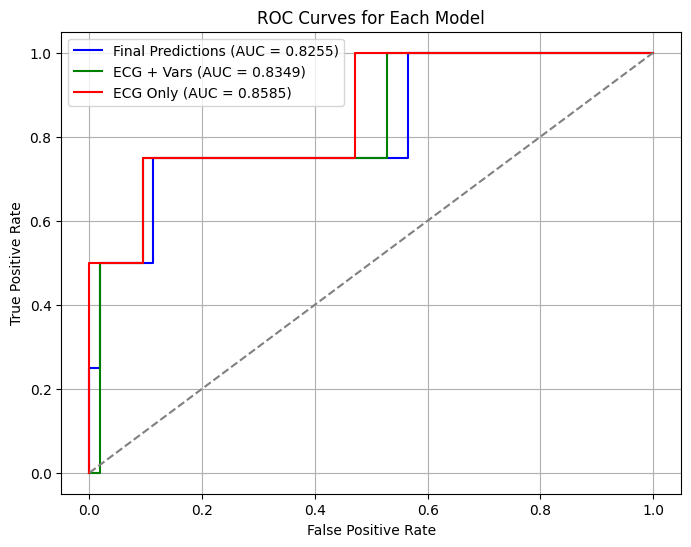

In [41]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import roc_curve, roc_auc_score

# Define a color map for the models
colors = ["blue", "green", "red"]

# Initialize the plot
plt.figure(figsize=(8, 6))

# Loop over all three prediction sets
for name, preds, color in zip(
    ["Final Predictions", "ECG + Vars", "ECG Only"],
    [predictions, predictions_ECG_with_Var, predictions_ECG],
    colors,
):
    # Compute ROC curve
    fpr, tpr, _ = roc_curve(t_y, preds)
    auc_score = roc_auc_score(t_y, preds)

    # Plot ROC curve
    plt.plot(fpr, tpr, color=color, label=f"{name} (AUC = {auc_score:.4f})")

# Plot diagonal line for reference
plt.plot([0, 1], [0, 1], linestyle="--", color="gray")

# Customize plot
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curves for Each Model")
plt.legend()
plt.grid(True)

# Show plot
plt.show()


In [ ]:
L = ["Correspondance dossier 2","AgeatDx","LTVA01","npy_path"]
df_f = result_df[L]
df_f["ECG_Score(Predictions)"] = predictions
df_f.to_excel("Training_Set_ECG_Score_One_ECG.xlsx")

/tmp/ipykernel_83091/2564114625.py:3: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_f["ECG_Score(Predictions)"] = predictions


In [ ]:
from sklearn.preprocessing import StandardScaler
scaler = StandardScaler()



def load_and_preprocess_ecg(path):
    with open(path, 'rb') as f:
          ecg = np.load(f)
          a,b,c = ecg.shape
          scaler.fit(ecg.reshape(a*b*c).reshape(-1,1))
          ecg = scaler.transform(ecg.reshape(a*b*c).reshape(-1,1))
          ecg = np.squeeze(ecg.reshape((c,a,b)))

    return ecg
def process_data_with_vars(test_cv, col):
    test_ECG_path = test_cv["npy_path"].values.tolist()
    label = test_cv["LTVA01"]
    test_features = np.array(test_cv[col].values,dtype= np.float32)
    test___data__ = np.empty([len(test_ECG_path),2500,12])
    for i, path in enumerate(test_ECG_path):
        test___data__[i,:,:] = load_and_preprocess_ecg(path)
    return test___data__, test_features,label

def process_data(test_cv):
    test_ECG_path = test_cv["npy_path"].values.tolist()
    label = test_cv["LTVA01"]
    test___data__ = np.empty([len(test_ECG_path),2500,12])
    for i, path in enumerate(test_ECG_path):
        test___data__[i,:,:] = load_and_preprocess_ecg(path)
    return test___data__, label
    


In [ ]:
def results_():
    result = {}
    result_df = test_cv.groupby("MRN").tail(1)
    result_df = result_df.groupby("MRN").filter(lambda x: len(x) == 1)
    test___data__,t_f, t_y = process_data_with_vars(result_df,col)
    test_dataset_ecg_with_vars = DataGenerator(test___data__, t_f,np.array(t_y).astype(np.float32), batch_size=256, shuffle=False)
    predictions_ECG_with_Var = loaded_model_ecg_with_var.predict(test_dataset_ecg_with_vars, verbose=1)
    
    test___data__, t_y = process_data(result_df)
    test_dataset_ecg = DataGeneratorECG(test___data__, np.array(t_y).astype(np.float32), batch_size=256, shuffle=False)
    predictions_ECG = loaded_model_ecg.predict(test_dataset_ecg, verbose=1)

    #X_rf = result_df[train_CV.columns[4:13]]
    #clf_rf = load('dataset/random_forest_classifier.joblib')
    #rf_prediction = clf_rf.predict_proba(X_rf)[:, 1]

    predictions = pred_final(predictions_ECG=predictions_ECG,predictions_ECG_with_Var=predictions_ECG_with_Var)
    return  predictions,t_y,result_df
predictions,t_y,result_df = results_()

In [ ]:
predictions,t_y,result_df = results_()

1/1 [==============================] - 0s 82ms/step


<h2> All the ecg </h2>

In [ ]:
import os
os.environ["CUDA_DEVICE_ORDER"] = "PCI_BUS_ID"
os.environ['CUDA_VISIBLE_DEVICES'] = '-1'
col = ["Age"]#,#,,
t_features = np.array(test_cv[col].values,dtype= np.float32)
test_dataset_ecg_with_vars = DataGenerator(test___data, t_features,np.array(y_test).astype(np.float32), batch_size=256, shuffle=False)



model_path = 'Models/model_Resnet_50_ecg_With_Vars.h5'



loaded_model_ecg_with_var = tf.keras.models.load_model(model_path, custom_objects={'custom_loss_with_regularization': custom_loss_with_regularization})
predictions_ECG_with_Var = loaded_model_ecg_with_var.predict(test_dataset_ecg_with_vars, verbose=1)

test_dataset_ecg = DataGeneratorECG(test___data, np.array(y_test).astype(np.float32), batch_size=256, shuffle=False)

model_path = 'pretrain_models/model_Resnet_50_ecg.h5'

# Load the model and provide the custom loss function in the custom_objects parameter
loaded_model_ecg = tf.keras.models.load_model(model_path, custom_objects={'custom_loss_with_regularization': custom_loss_with_regularization})
predictions_ECG = loaded_model_ecg.predict(test_dataset_ecg, verbose=1)
full_prediction = pred_final(predictions_ECG=predictions_ECG,predictions_ECG_with_Var=predictions_ECG_with_Var)
ids = test_cv["MRN"].values.tolist()


2/2 [==============================] - 8s 2s/step


In [54]:
import numpy as np
import pandas as pd

# Convert everything to NumPy arrays for consistency
ids = np.array(ids)
y_test = np.array(y_test).flatten()  # Ensure y_test is 1D
predictions_ECG = np.array(predictions_ECG).flatten()  # Flatten if needed
predictions_ECG_with_Var = np.array(predictions_ECG_with_Var).flatten()  # Flatten if needed
Ensemble = np.array(full_prediction).flatten()  # Flatten if needed

# Create a DataFrame with all values
df = pd.DataFrame({
    'Patient_ID': ids,
    'y_test': y_test,
    'predictions_ECG': predictions_ECG,
    'predictions_ECG_with_Age': predictions_ECG_with_Var,
    'Ensemble_model': Ensemble
})

# Compute the mean prediction for each patient, including y_test
mean_df = df.groupby("Patient_ID").agg({
    'y_test': 'mean',  # Should be constant per patient, but taking mean just in case
    'predictions_ECG': 'mean',
    'predictions_ECG_with_Age': 'mean',
    'Ensemble_model': 'mean'
}).reset_index()

# Display results
print(mean_df.shape)
mean_df.head()

(57, 5)


,Patient_ID,y_test,predictions_ECG,predictions_ECG_with_Age,Ensemble_model
0,113058,0.0,0.004474,0.053901,0.029188
1,231060,0.0,0.001150,0.005575,0.003363
2,241068,1.0,0.504321,0.368965,0.436643
3,316405,0.0,0.000663,0.007437,0.004050
4,325520,0.0,0.001618,0.012861,0.007239


In [75]:
import numpy as np
import pandas as pd
from sklearn.metrics import roc_auc_score, average_precision_score, confusion_matrix
import math

# -------------------------
# Helper functions
# -------------------------
def wilson_ci(k, n, z=1.96):
    """Wilson score interval for a proportion (returns lower, upper in [0,1])."""
    if n == 0:
        return (np.nan, np.nan)
    phat = k / n
    denom = 1 + (z**2)/n
    center = phat + (z**2) / (2*n)
    adj = z * math.sqrt((phat*(1-phat) + (z**2)/(4*n)) / n)
    lower = (center - adj) / denom
    upper = (center + adj) / denom
    lower = max(0.0, lower)
    upper = min(1.0, upper)
    return lower, upper

def dor_and_ci_from_counts(tp, fp, fn, tn, z=1.96, cc=1.0):
    tp_c, fp_c, fn_c, tn_c = tp + cc, fp + cc, fn + cc, tn + cc
    dor = (tp_c * tn_c) / (fp_c * fn_c)
    log_dor = np.log(dor)
    se_log = np.sqrt(1/tp_c + 1/fn_c + 1/fp_c + 1/tn_c)
    low, high = np.exp([log_dor - z*se_log, log_dor + z*se_log])
    return dor, low, high

def bootstrap_auc_ap(y_true, y_pred, metric='auc', n_bootstrap=2000, seed=42):
    """
    Bootstrap CI for AUROC or AUPRC.
    Skips resamples where only one class present.
    Returns (point_estimate, lower, upper, n_valid_resamples)
    """
    rng = np.random.RandomState(seed)
    n = len(y_true)
    vals = []
    for i in range(n_bootstrap):
        idx = rng.randint(0, n, n)  # sample with replacement
        y_t = y_true[idx]
        y_p = y_pred[idx]
        # require both classes present
        if y_t.sum() == 0 or y_t.sum() == n:
            continue
        try:
            if metric == 'auc':
                v = roc_auc_score(y_t, y_p)
            elif metric == 'ap':
                v = average_precision_score(y_t, y_p)
            else:
                raise ValueError('metric must be "auc" or "ap"')
            vals.append(v)
        except Exception:
            continue
    if len(vals) == 0:
        return (np.nan, np.nan, np.nan, 0)
    vals = np.array(vals)
    pt = roc_auc_score(y_true, y_pred) if metric=='auc' else average_precision_score(y_true, y_pred)
    low, high = np.nanpercentile(vals, [2.5, 97.5])
    return pt, low, high, len(vals)

# -------------------------
# Main function
# -------------------------
def compute_robust_metrics(y_true, y_pred, threshold=0.004, n_bootstrap=2000, seed=42):
    y_true = np.array(y_true).astype(int)
    y_pred = np.array(y_pred).flatten()
    n = len(y_true)
    prevalence = 100.0 * y_true.mean()

    # Binary predictions
    y_bin = (y_pred >= threshold).astype(int)

    # confusion matrix
    tn, fp, fn, tp = confusion_matrix(y_true, y_bin).ravel()

    # Proportions (point estimates)
    sens = tp / (tp + fn) if (tp + fn) > 0 else np.nan
    spec = tn / (tn + fp) if (tn + fp) > 0 else np.nan
    ppv  = tp / (tp + fp) if (tp + fp) > 0 else np.nan
    npv  = tn / (tn + fn) if (tn + fn) > 0 else np.nan

    # DOR with continuity correction when needed
    dor_pt, dor_low, dor_high = dor_and_ci_from_counts(tp, fp, fn, tn, z=1.96, cc=0.5)

    # CIs for proportions using Wilson
    sens_low, sens_high = wilson_ci(tp, tp+fn)
    spec_low, spec_high = wilson_ci(tn, tn+fp)
    ppv_low, ppv_high = wilson_ci(tp, tp+fp)
    npv_low, npv_high = wilson_ci(tn, tn+fn)

    # AUROC and AUPRC bootstrap with skipping invalid resamples
    auc_pt, auc_low, auc_high, auc_valid = bootstrap_auc_ap(y_true, y_pred, metric='auc', n_bootstrap=n_bootstrap, seed=seed)
    ap_pt, ap_low, ap_high, ap_valid = bootstrap_auc_ap(y_true, y_pred, metric='ap', n_bootstrap=n_bootstrap, seed=seed+1)

    # package results
    res = {
        'N': n,
        'Prevalence (%)': prevalence,
        'AUROC (95% CI)': f"{auc_pt:.2f} ({auc_low:.2f}-{auc_high:.2f})" if not np.isnan(auc_pt) else "nan",
        'AUPRC (95% CI)': f"{ap_pt:.2f} ({ap_low:.2f}-{ap_high:.2f})" if not np.isnan(ap_pt) else "nan",
        'DOR (95% CI)': f"{dor_pt:.2f} ({dor_low:.2f}-{dor_high:.2f})",
        'Sensitivity (95% CI)': f"{sens:.2f} ({sens_low:.2f}-{sens_high:.2f})",
        'Specificity (95% CI)': f"{spec:.2f} ({spec_low:.2f}-{spec_high:.2f})",
        'PPV (95% CI)': f"{ppv:.2f} ({ppv_low:.2f}-{ppv_high:.2f})" if not np.isnan(ppv) else "nan",
        'NPV (95% CI)': f"{npv:.2f} ({npv_low:.2f}-{npv_high:.2f})" if not np.isnan(npv) else "nan",
        # extras for diagnostics
        '_tp_fp_fn_tn': (tp, fp, fn, tn),
        '_auc_valid_bootstraps': auc_valid,
        '_ap_valid_bootstraps': ap_valid
    }
    return res

# -------------------------
# Example usage with your arrays:
# -------------------------


res_ecg = compute_robust_metrics(mean_df["y_test"], mean_df["predictions_ECG"], threshold=0.004, n_bootstrap=2000, seed=42)
res_ecg_age = compute_robust_metrics(mean_df["y_test"], mean_df["predictions_ECG_with_Age"], threshold=0.004, n_bootstrap=2000, seed=99)

table = pd.DataFrame([res_ecg, res_ecg_age],
                     index=['ECG-ML (Mean of all ECGs)', 'ECG-ML + Age (Mean of all ECGs)'])

# drop diagnostic-only columns
table_display = table.drop(columns=['_tp_fp_fn_tn', '_auc_valid_bootstraps', '_ap_valid_bootstraps'])
table_display.head()
# If you want to inspect the confusion counts and bootstrap counts:


,N,Prevalence (%),AUROC (95% CI),AUPRC (95% CI),DOR (95% CI),Sensitivity (95% CI),Specificity (95% CI),PPV (95% CI),NPV (95% CI)
ECG-ML (Mean of all ECGs),57,7.017544,0.89 (0.72-1.00),0.62 (0.09-1.00),12.49 (1.61-96.85),0.75 (0.30-0.95),0.85 (0.73-0.92),0.27 (0.10-0.57),0.98 (0.89-1.00)
ECG-ML + Age (Mean of all ECGs),57,7.017544,0.84 (0.65-1.00),0.38 (0.07-1.00),0.26 (0.01-7.27),1.00 (0.51-1.00),0.02 (0.00-0.10),0.07 (0.03-0.17),1.00 (0.21-1.00)


Confusion Matrix for ECG Model:


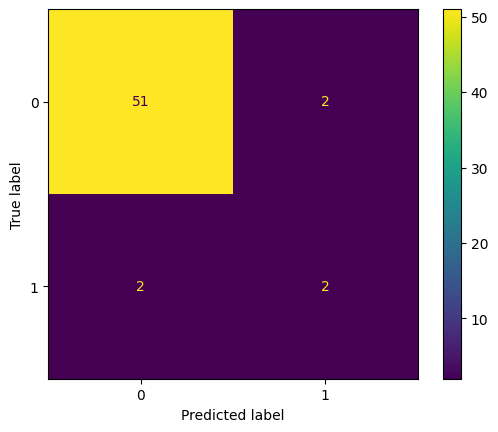


Classification Report for ECG Model:
              precision    recall  f1-score   support

         0.0       0.96      0.96      0.96        53
         1.0       0.50      0.50      0.50         4

    accuracy                           0.93        57
   macro avg       0.73      0.73      0.73        57
weighted avg       0.93      0.93      0.93        57


Sensitivity (Recall) for ECG Model: 0.5000
Specificity for ECG Model: 0.9623

Positive Predictive Value (PPV) for ECG Model: 0.5000
Negative Predictive Value (NPV) for ECG Model: 0.9623


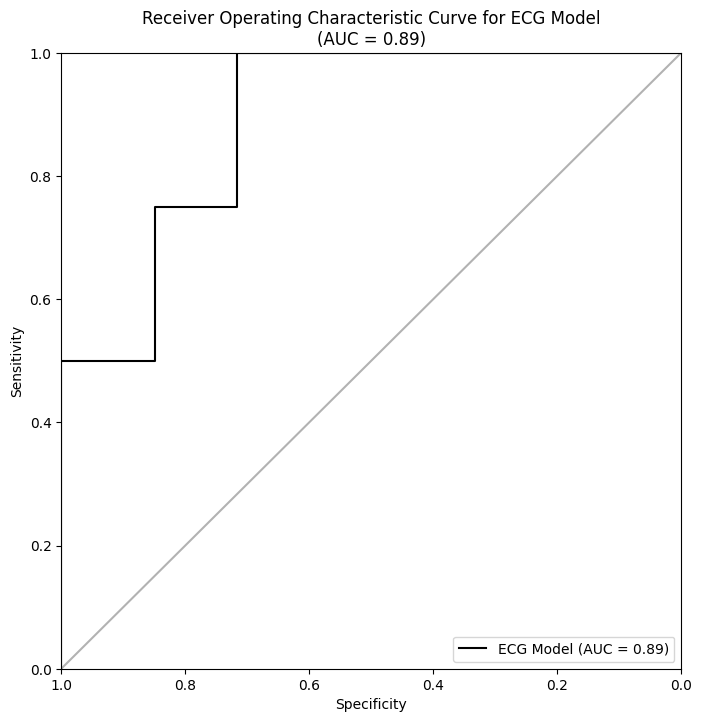

Confusion Matrix for ECG and Age  Model:


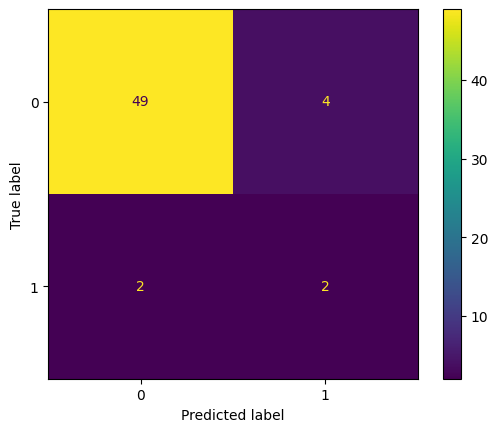


Classification Report for ECG and Age  Model:
              precision    recall  f1-score   support

         0.0       0.96      0.92      0.94        53
         1.0       0.33      0.50      0.40         4

    accuracy                           0.89        57
   macro avg       0.65      0.71      0.67        57
weighted avg       0.92      0.89      0.90        57


Sensitivity (Recall) for ECG and Age  Model: 0.5000
Specificity for ECG and Age  Model: 0.9245

Positive Predictive Value (PPV) for ECG and Age  Model: 0.3333
Negative Predictive Value (NPV) for ECG and Age  Model: 0.9608


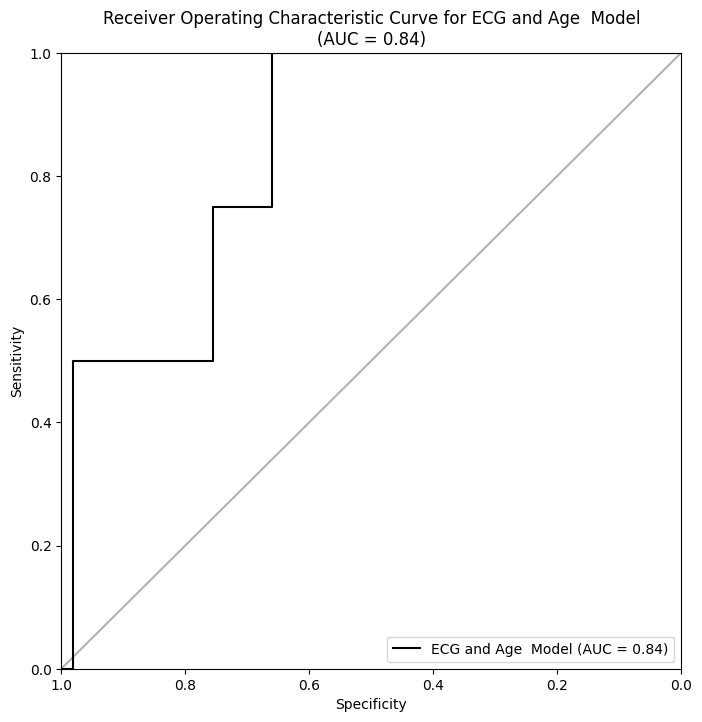

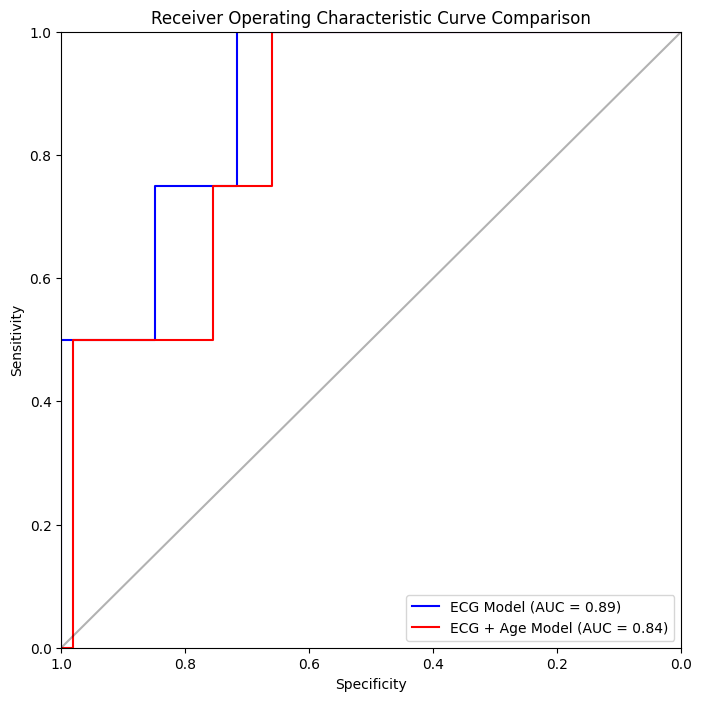

In [ ]:
from sklearn.metrics import (confusion_matrix, roc_auc_score, roc_curve, auc, 
                             classification_report, ConfusionMatrixDisplay)
import matplotlib.pyplot as plt
import numpy as np

def plot_results(predictions, test_label, model_name):

    
    # Convert predictions to binary labels based on a threshold of 0.01
    binary_predictions = (predictions > 0.1).astype(int)
    
    # Compute the confusion matrix
    cm = confusion_matrix(test_label, binary_predictions)
    print(f"Confusion Matrix for {model_name}:")
    disp = ConfusionMatrixDisplay(confusion_matrix=cm)
    disp.plot()
    plt.show()
    
    # Print Classification Report
    print(f"\nClassification Report for {model_name}:")
    print(classification_report(test_label, binary_predictions))
    
    # Extract TN, FP, FN, TP from confusion matrix
    tn, fp, fn, tp = cm.ravel()
    
    # Compute Sensitivity (Recall), Specificity, PPV, and NPV
    sensitivity = tp / (tp + fn) if (tp + fn) > 0 else 0
    specificity = tn / (tn + fp) if (tn + fp) > 0 else 0
    ppv = tp / (tp + fp) if (tp + fp) > 0 else 0
    npv = tn / (tn + fn) if (tn + fn) > 0 else 0
    
    print(f"\nSensitivity (Recall) for {model_name}: {sensitivity:.4f}")
    print(f"Specificity for {model_name}: {specificity:.4f}")
    print(f"\nPositive Predictive Value (PPV) for {model_name}: {ppv:.4f}")
    print(f"Negative Predictive Value (NPV) for {model_name}: {npv:.4f}")
    
    # Compute ROC Curve and AUC (Sensitivity vs. 1 - Specificity)
    fpr, tpr, _ = roc_curve(test_label, predictions)
    roc_auc = auc(fpr, tpr)
    spec = [1 - x for x in fpr]
    
    # Plot ROC Curve
    plt.figure(figsize=(8, 8))
    ax = plt.axes()
    ax.set_title(
        f'Receiver Operating Characteristic Curve for {model_name}\n'
        f'(AUC = {roc_auc:.2f})'
    )
    ax.plot(spec, tpr, 'k-', label=f'{model_name} (AUC = {roc_auc:.2f})')
    ax.plot([1, 0], [0, 1], 'k-', alpha=0.3)
    ax.set_xlim([1, 0])
    ax.set_ylim([0, 1])
    ax.set_xlabel('Specificity')
    ax.set_ylabel('Sensitivity')
    ax.legend()
    plt.show()

def plot_comparison(predictions1, predictions2, test_label,CI, model1_name, model2_name):
    """
    Function to plot and compare ROC curves for three models.
    """
    # ROC for Model 1
    fpr1, tpr1, _ = roc_curve(test_label, predictions1)
    roc_auc1 = auc(fpr1, tpr1)
    spec1 = [1 - x for x in fpr1]

    # ROC for Model 2
    fpr2, tpr2, _ = roc_curve(test_label, predictions2)
    roc_auc2 = auc(fpr2, tpr2)
    spec2 = [1 - x for x in fpr2]

    # ROC for Model 3
 

    # Plot all ROC curves
    plt.figure(figsize=(8, 8))
    ax = plt.axes()
    ax.set_title('Receiver Operating Characteristic Curve Comparison')
    ax.plot(spec1, tpr1, 'b-', label=f'{model1_name}: AUC = {roc_auc1:.2f}')
    ax.plot(spec2, tpr2, 'r-', label=f'{model2_name}: AUC = {roc_auc2:.2f}')
    ax.plot([1, 0], [0, 1], 'k-', alpha=0.3)  # Diagonale
    ax.set_xlim([1, 0])
    ax.set_ylim([0, 1])
    ax.set_xlabel('Specificity')
    ax.set_ylabel('Sensitivity')
    ax.legend()
    plt.show()
    
from sklearn.calibration import calibration_curve
import matplotlib.pyplot as plt

def plot_calibration_curve(predictions, test_label, model_name, n_bins=10):
    """
    Plots a calibration curve (reliability diagram).
    
    Parameters:
    - predictions: Array of predicted probabilities.
    - test_label: True binary labels.
    - model_name: Name of the model for plotting.
    - n_bins: Number of bins to discretize predicted probabilities.
    """
    prob_true, prob_pred = calibration_curve(test_label, predictions, n_bins=n_bins, strategy='uniform')

    plt.figure(figsize=(8, 8))
    plt.plot(prob_pred, prob_true, marker='o', label=f'{model_name}')
    plt.plot([0, 1], [0, 1], linestyle='--', color='gray', label="Perfect Calibration")
    
    plt.xlabel("Predicted Probability")
    plt.ylabel("Observed Frequency")
    plt.title(f'Calibration Curve for {model_name}')
    plt.legend()
    plt.show()

# Example usage:
plot_results(mean_df["predictions_ECG"], mean_df["y_test"], 'ECG Model')
plot_results(mean_df["predictions_ECG_with_Age"], mean_df["y_test"], 'ECG and Age  Model')
plot_comparison(
    mean_df["predictions_ECG"], 
    mean_df["predictions_ECG_with_Age"], 
     mean_df["y_test"],
     ["(0.72-1.00)","0.84 (0.65-1.00)"],
    "ECG Model", 
    "ECG + Age Model"
)

#plot_calibration_curve(mean_df["predictions_ECG"], mean_df["y_test"], 'ECG Model')
#plot_calibration_curve(mean_df["full_prediction"], mean_df["y_test"], 'Final Prediction Model')


In [49]:
import numpy as np
from sklearn.utils import resample
from sklearn.metrics import roc_auc_score

# Define the number of bootstrap iterations
n_iterations = 1000

# Dictionary to store results
auc_results = {}

# Loop over all three prediction sets    ,  
for name, preds in zip(["ECG + Vars", "ECG Only"],
                       [mean_df["predictions_ECG_with_Age"], mean_df["predictions_ECG"]]):

    # Compute AUC on full dataset
    auc_score = roc_auc_score(mean_df["y_test"], preds)

    # Initialize list for bootstrap AUCs
    auc_values = []

    # Perform bootstrapping
    for _ in range(n_iterations):
        y_boot, y_pred_boot = resample(mean_df["y_test"], preds, replace=True)
        
        # Compute AUC only if both classes are present in the resampled set
        if len(np.unique(y_boot)) == 2:
            auc_values.append(roc_auc_score(y_boot, y_pred_boot))

    # Compute confidence interval
    auc_ci = np.percentile(auc_values, [2.5, 97.5])

    # Store results
    auc_results[name] = {
        "AUC": auc_score,
        "95% CI": (auc_ci[0], auc_ci[1])
    }

# Print results
for model, res in auc_results.items():
    print(f"\n{model}: AUC = {res['AUC']:.4f}, 95% CI = ({res['95% CI'][0]:.4f}, {res['95% CI'][1]:.4f})")


ECG + Vars: AUC = 0.8443, 95% CI = (0.6727, 1.0000)

ECG Only: AUC = 0.8915, 95% CI = (0.7321, 1.0000)


<h1> the earlist ECG </h1>

In [ ]:
def results_():
    result = {}
    result_df = test_cv.groupby("MRN").tail(1)
    result_df = result_df.groupby("MRN").filter(lambda x: len(x) == 1)
    test___data__,t_f, t_y = process_data_with_vars(result_df,col)
    test_dataset_ecg_with_vars = DataGenerator(test___data__, t_f,np.array(t_y).astype(np.float32), batch_size=256, shuffle=False)
    predictions_ECG_with_Var = loaded_model_ecg_with_var.predict(test_dataset_ecg_with_vars, verbose=1)
    
    test___data__, t_y = process_data(result_df)
    test_dataset_ecg = DataGeneratorECG(test___data__, np.array(t_y).astype(np.float32), batch_size=256, shuffle=False)
    predictions_ECG = loaded_model_ecg.predict(test_dataset_ecg, verbose=1)

    return  predictions_ECG,predictions_ECG_with_Var,t_y,result_df
predictions_ECG,predictions_ECG_with_Var,t_y,result_df= results_()

1/1 [==============================] - 0s 287ms/step


Confusion Matrix for ECG Model:


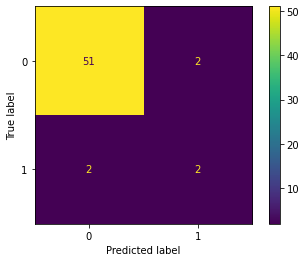


Classification Report for ECG Model:
              precision    recall  f1-score   support

           0       0.96      0.96      0.96        53
           1       0.50      0.50      0.50         4

    accuracy                           0.93        57
   macro avg       0.73      0.73      0.73        57
weighted avg       0.93      0.93      0.93        57


Sensitivity (Recall) for ECG Model: 0.5000
Specificity for ECG Model: 0.9623

Positive Predictive Value (PPV) for ECG Model: 0.5000
Negative Predictive Value (NPV) for ECG Model: 0.9623


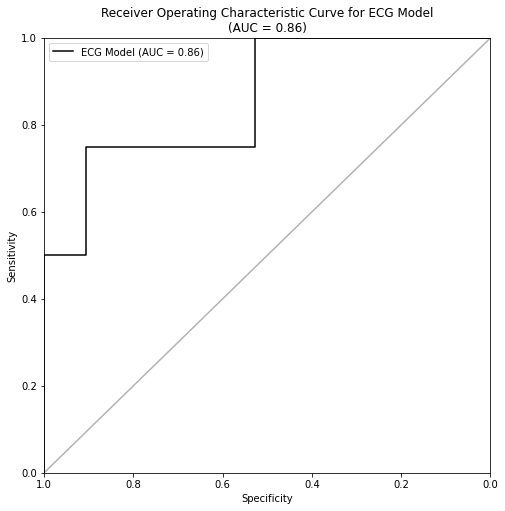

Confusion Matrix for ECG and Age  Model:


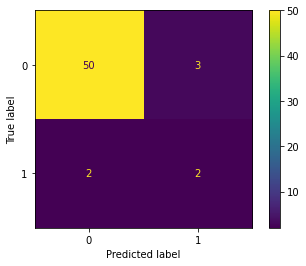


Classification Report for ECG and Age  Model:
              precision    recall  f1-score   support

           0       0.96      0.94      0.95        53
           1       0.40      0.50      0.44         4

    accuracy                           0.91        57
   macro avg       0.68      0.72      0.70        57
weighted avg       0.92      0.91      0.92        57


Sensitivity (Recall) for ECG and Age  Model: 0.5000
Specificity for ECG and Age  Model: 0.9434

Positive Predictive Value (PPV) for ECG and Age  Model: 0.4000
Negative Predictive Value (NPV) for ECG and Age  Model: 0.9615


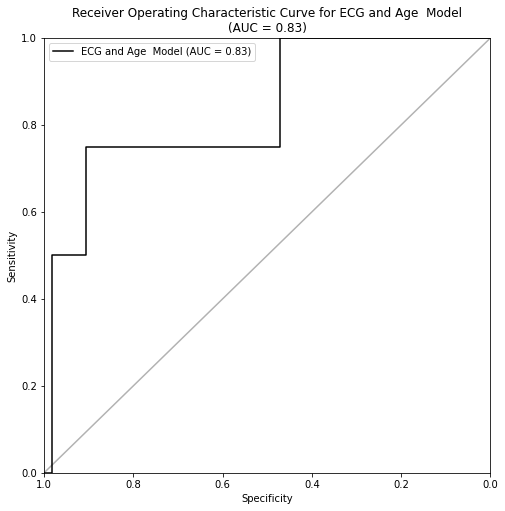

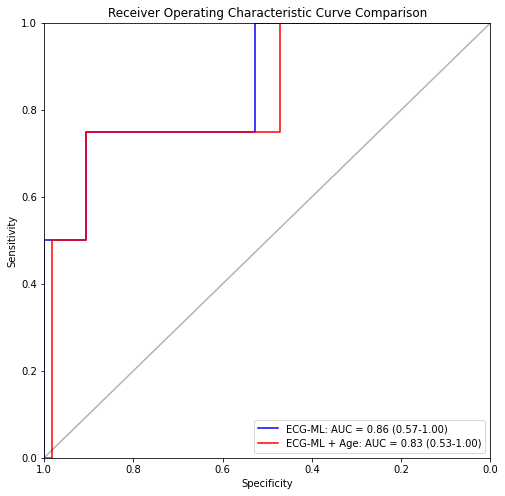

In [61]:
from sklearn.metrics import (confusion_matrix, roc_auc_score, roc_curve, auc, 
                             classification_report, ConfusionMatrixDisplay)
import matplotlib.pyplot as plt
import numpy as np

def plot_results(predictions, test_label, model_name):
    """
    Function to evaluate classification performance using various metrics, including:
    - Confusion Matrix
    - Classification Report
    - Sensitivity (Recall) and Specificity
    - Positive Predictive Value (PPV) and Negative Predictive Value (NPV)
    - ROC Curve (Sensitivity vs. 1 - Specificity)
    """
    
    # Convert predictions to binary labels based on a threshold of 0.01
    binary_predictions = (predictions > 0.1).astype(int)
    
    # Compute the confusion matrix
    cm = confusion_matrix(test_label, binary_predictions)
    print(f"Confusion Matrix for {model_name}:")
    disp = ConfusionMatrixDisplay(confusion_matrix=cm)
    disp.plot()
    plt.show()
    
    # Print Classification Report
    print(f"\nClassification Report for {model_name}:")
    print(classification_report(test_label, binary_predictions))
    
    # Extract TN, FP, FN, TP from confusion matrix
    tn, fp, fn, tp = cm.ravel()
    
    # Compute Sensitivity (Recall), Specificity, PPV, and NPV
    sensitivity = tp / (tp + fn) if (tp + fn) > 0 else 0
    specificity = tn / (tn + fp) if (tn + fp) > 0 else 0
    ppv = tp / (tp + fp) if (tp + fp) > 0 else 0
    npv = tn / (tn + fn) if (tn + fn) > 0 else 0
    
    print(f"\nSensitivity (Recall) for {model_name}: {sensitivity:.4f}")
    print(f"Specificity for {model_name}: {specificity:.4f}")
    print(f"\nPositive Predictive Value (PPV) for {model_name}: {ppv:.4f}")
    print(f"Negative Predictive Value (NPV) for {model_name}: {npv:.4f}")
    
    # Compute ROC Curve and AUC (Sensitivity vs. 1 - Specificity)
    fpr, tpr, _ = roc_curve(test_label, predictions)
    roc_auc = auc(fpr, tpr)
    spec = [1 - x for x in fpr]
    
    # Plot ROC Curve
    plt.figure(figsize=(8, 8))
    ax = plt.axes()
    ax.set_title(
        f'Receiver Operating Characteristic Curve for {model_name}\n'
        f'(AUC = {roc_auc:.2f})'
    )
    ax.plot(spec, tpr, 'k-', label=f'{model_name} (AUC = {roc_auc:.2f})')
    ax.plot([1, 0], [0, 1], 'k-', alpha=0.3)
    ax.set_xlim([1, 0])
    ax.set_ylim([0, 1])
    ax.set_xlabel('Specificity')
    ax.set_ylabel('Sensitivity')
    ax.legend()
    plt.show()

def plot_comparison(predictions1, predictions2, test_label,CI, model1_name, model2_name):
    """
    Function to plot and compare ROC curves for three models.
    """
    # ROC for Model 1
    fpr1, tpr1, _ = roc_curve(test_label, predictions1)
    roc_auc1 = auc(fpr1, tpr1)
    spec1 = [1 - x for x in fpr1]

    # ROC for Model 2
    fpr2, tpr2, _ = roc_curve(test_label, predictions2)
    roc_auc2 = auc(fpr2, tpr2)
    spec2 = [1 - x for x in fpr2]

    # ROC for Model 3
 

    # Plot all ROC curves
    plt.figure(figsize=(8, 8))
    ax = plt.axes()
    ax.set_title('Receiver Operating Characteristic Curve Comparison')
    ax.plot(spec1, tpr1, 'b-', label=f'{model1_name}: AUC = {roc_auc1:.2f} {CI[0]}')
    ax.plot(spec2, tpr2, 'r-', label=f'{model2_name}: AUC = {roc_auc2:.2f} {CI[1]}')
    ax.plot([1, 0], [0, 1], 'k-', alpha=0.3)  # Diagonale
    ax.set_xlim([1, 0])
    ax.set_ylim([0, 1])
    ax.set_xlabel('Specificity')
    ax.set_ylabel('Sensitivity')
    ax.legend()
    plt.show()
    
from sklearn.calibration import calibration_curve
import matplotlib.pyplot as plt

def plot_calibration_curve(predictions, test_label, model_name, n_bins=10):
    """
    Plots a calibration curve (reliability diagram).
    
    Parameters:
    - predictions: Array of predicted probabilities.
    - test_label: True binary labels.
    - model_name: Name of the model for plotting.
    - n_bins: Number of bins to discretize predicted probabilities.
    """
    prob_true, prob_pred = calibration_curve(test_label, predictions, n_bins=n_bins, strategy='uniform')

    plt.figure(figsize=(8, 8))
    plt.plot(prob_pred, prob_true, marker='o', label=f'{model_name}')
    plt.plot([0, 1], [0, 1], linestyle='--', color='gray', label="Perfect Calibration")
    
    plt.xlabel("Predicted Probability")
    plt.ylabel("Observed Frequency")
    plt.title(f'Calibration Curve for {model_name}')
    plt.legend()
    plt.show()

# Example usage: predictions_ECG,predictions_ECG_with_Var,t_y,result_df= results_()
plot_results(predictions_ECG, t_y, 'ECG Model')
plot_results(predictions_ECG_with_Var, t_y, 'ECG and Age  Model')
CI = ["(0.57-1.00)", "(0.53-1.00)"]
plot_comparison(
    predictions_ECG, 
    predictions_ECG_with_Var, 
     t_y,
     CI,
    "ECG-ML", 
    "ECG-ML + Age"
)

In [50]:
import numpy as np
from sklearn.utils import resample
from sklearn.metrics import roc_auc_score

# Define the number of bootstrap iterations
n_iterations = 1000

# Dictionary to store results
auc_results = {}

# Loop over all three prediction sets   
"""
    predictions_ECG, 
    predictions_ECG_with_Var, 
     t_y,
""" 
for name, preds in zip(["ECG + Vars", "ECG Only"],
                       [predictions_ECG_with_Var, predictions_ECG]):

    # Compute AUC on full dataset
    auc_score = roc_auc_score(t_y, preds)

    # Initialize list for bootstrap AUCs
    auc_values = []

    # Perform bootstrapping
    for _ in range(n_iterations):
        y_boot, y_pred_boot = resample(t_y, preds, replace=True)
        
        # Compute AUC only if both classes are present in the resampled set
        if len(np.unique(y_boot)) == 2:
            auc_values.append(roc_auc_score(y_boot, y_pred_boot))

    # Compute confidence interval
    auc_ci = np.percentile(auc_values, [2.5, 97.5])

    # Store results
    auc_results[name] = {
        "AUC": auc_score,
        "95% CI": (auc_ci[0], auc_ci[1])
    }

# Print results
for model, res in auc_results.items():
    print(f"\n{model}: AUC = {res['AUC']:.4f}, 95% CI = ({res['95% CI'][0]:.4f}, {res['95% CI'][1]:.4f})")


ECG + Vars: AUC = 0.8349, 95% CI = (0.5228, 1.0000)

ECG Only: AUC = 0.8585, 95% CI = (0.5692, 1.0000)


In [46]:
def show_results_(r = 10):
    result = {}
    number_of_patients = []
    for i in range(1,r+1):
        result_df = test_cv.groupby("MRN").tail(i)
        result_df = result_df.groupby("MRN").filter(lambda x: len(x) == i)
        number_p = len(result_df['MRN'].unique())
        
        number_of_patients.append(number_p)


        test___data__,t_f, t_y = process_data_with_vars(result_df,col)
        test_dataset_ecg_with_vars = DataGenerator(test___data__, t_f,np.array(t_y).astype(np.float32), batch_size=256, shuffle=False)
        predictions_ECG_with_Var = loaded_model_ecg_with_var.predict(test_dataset_ecg_with_vars, verbose=1)
        
        test___data__, t_y = process_data(result_df)
        test_dataset_ecg = DataGeneratorECG(test___data__, np.array(t_y).astype(np.float32), batch_size=256, shuffle=False)
        predictions_ECG = loaded_model_ecg.predict(test_dataset_ecg, verbose=1)

        #X_rf = result_df[train_CV.columns[4:13]]
        #clf_rf = load('dataset/random_forest_classifier.joblib')
        #rf_prediction = clf_rf.predict_proba(X_rf)[:, 1]

        predictions = pred_final(predictions_ECG=predictions_ECG,predictions_ECG_with_Var=predictions_ECG_with_Var)
        
        #label = [float(i[0]) for i in y_true]
        result_df["predictions"] = predictions
        result_df["predictions"] = pd.to_numeric(result_df["predictions"], errors="coerce")

        #df_prediction = pd.concat([result_df["MHI MRN"],result_df["predictions"],result_df['Fam_positive_strict'] ],axis=1)
        #mean_df = result_df.groupby("MRN").mean()
        mean_df = result_df.groupby("MRN").mean(numeric_only=True)

        predictions = mean_df["predictions"].values.tolist()
        predictions =np.array(predictions)
        t_y = mean_df["LTVA01"].values.tolist()
        fpr, tpr, thresholds = roc_curve(t_y, predictions)
        roc_auc = auc(fpr, tpr)
        result[i] = roc_auc
    data__ = {"ECGs_to_select": list(result.keys()),"AUC  test Patients Level":list(result.values()),"number_of_patients":number_of_patients}
    return pd.DataFrame(data__)
r_df = show_results_(r = 6)

r_df.head()

1/1 [==============================] - 0s 278ms/step


,ECGs_to_select,AUC test Patients Level,number_of_patients
0,1,0.825472,57
1,2,0.851190,46
2,3,0.885714,39
3,4,0.929688,36
4,5,0.869565,27


In [47]:
def show_results_(r = 10):
    result = {}
    number_of_patients = []
    for i in range(1,r+1):
        result_df = test_cv.groupby("MRN").tail(i)
        result_df = result_df.groupby("MRN").filter(lambda x: len(x) == i)
        number_p = len(result_df['MRN'].unique())
        
        number_of_patients.append(number_p)


        test___data__,t_f, t_y = process_data_with_vars(result_df,col)
        test_dataset_ecg_with_vars = DataGenerator(test___data__, t_f,np.array(t_y).astype(np.float32), batch_size=256, shuffle=False)
        predictions_ECG_with_Var = loaded_model_ecg_with_var.predict(test_dataset_ecg_with_vars, verbose=1)
        
        test___data__, t_y = process_data(result_df)
        test_dataset_ecg = DataGeneratorECG(test___data__, np.array(t_y).astype(np.float32), batch_size=256, shuffle=False)
        predictions_ECG = loaded_model_ecg.predict(test_dataset_ecg, verbose=1)

        #X_rf = result_df[train_CV.columns[4:13]]
        #clf_rf = load('dataset/random_forest_classifier.joblib')
        #rf_prediction = clf_rf.predict_proba(X_rf)[:, 1]

        #predictions = pred_final(predictions_ECG=predictions_ECG,predictions_ECG_with_Var=predictions_ECG_with_Var)
        predictions = predictions_ECG
        
        #label = [float(i[0]) for i in y_true]
        result_df["predictions"] = predictions
        result_df["predictions"] = pd.to_numeric(result_df["predictions"], errors="coerce")

        #df_prediction = pd.concat([result_df["MHI MRN"],result_df["predictions"],result_df['Fam_positive_strict'] ],axis=1)
        #mean_df = result_df.groupby("MRN").mean()
        mean_df = result_df.groupby("MRN").mean(numeric_only=True)

        predictions = mean_df["predictions"].values.tolist()
        predictions =np.array(predictions)
        t_y = mean_df["LTVA01"].values.tolist()
        fpr, tpr, thresholds = roc_curve(t_y, predictions)
        roc_auc = auc(fpr, tpr)
        result[i] = roc_auc
    data__ = {"ECGs_to_select": list(result.keys()),"AUC  test Patients Level":list(result.values()),"number_of_patients":number_of_patients}
    return pd.DataFrame(data__)
r_df_2 = show_results_(r = 6)

r_df_2.head()

1/1 [==============================] - 0s 335ms/step


,ECGs_to_select,AUC test Patients Level,number_of_patients
0,1,0.858491,57
1,2,0.827381,46
2,3,0.921429,39
3,4,0.898438,36
4,5,0.880435,27


In [ ]:
def show_results_(r = 10):
    result = {}
    number_of_patients = []
    for i in range(1,r+1):
        result_df = test_cv.groupby("MRN").tail(i)
        result_df = result_df.groupby("MRN").filter(lambda x: len(x) == i)
        number_p = len(result_df['MRN'].unique())
        
        number_of_patients.append(number_p)


        test___data__,t_f, t_y = process_data_with_vars(result_df,col)
        test_dataset_ecg_with_vars = DataGenerator(test___data__, t_f,np.array(t_y).astype(np.float32), batch_size=256, shuffle=False)
        predictions_ECG_with_Var = loaded_model_ecg_with_var.predict(test_dataset_ecg_with_vars, verbose=1)
        
        test___data__, t_y = process_data(result_df)
        test_dataset_ecg = DataGeneratorECG(test___data__, np.array(t_y).astype(np.float32), batch_size=256, shuffle=False)
        predictions_ECG = loaded_model_ecg.predict(test_dataset_ecg, verbose=1)

        #X_rf = result_df[train_CV.columns[4:13]]
        #clf_rf = load('dataset/random_forest_classifier.joblib')
        #rf_prediction = clf_rf.predict_proba(X_rf)[:, 1]

        #predictions = pred_final(predictions_ECG=predictions_ECG,predictions_ECG_with_Var=predictions_ECG_with_Var)
        predictions = predictions_ECG
        
        #label = [float(i[0]) for i in y_true]
        result_df["predictions"] = predictions
        result_df["predictions"] = pd.to_numeric(result_df["predictions"], errors="coerce")

        #df_prediction = pd.concat([result_df["MHI MRN"],result_df["predictions"],result_df['Fam_positive_strict'] ],axis=1)
        #mean_df = result_df.groupby("MRN").mean()
        mean_df = result_df.groupby("MRN").mean(numeric_only=True)

        predictions = mean_df["predictions"].values.tolist()
        predictions =np.array(predictions)
        t_y = mean_df["LTVA01"].values.tolist()
        fpr, tpr, thresholds = roc_curve(t_y, predictions)
        roc_auc = auc(fpr, tpr)
        result[i] = roc_auc
    data__ = {"ECGs_to_select": list(result.keys()),"AUC  test Patients Level":list(result.values()),"number_of_patients":number_of_patients}
    return pd.DataFrame(data__)
r_df_3 = show_results_(r = 6)

r_df_3.head()

1/1 [==============================] - 0s 317ms/step


,ECGs_to_select,AUC test Patients Level,number_of_patients
0,1,0.834906,57
1,2,0.892857,46
2,3,0.828571,39
3,4,0.953125,36
4,5,0.891304,27


In [ ]:
L = ["Correspondance dossier 2","AgeatDx","LTVA01","npy_path"]
df_f = result_df[L]
df_f["ECG_Score(Predictions)"] = predictions
df_f.to_excel("Test_Set_ECG_Score_One_ECG.xlsx")


/tmp/ipykernel_83091/2988991426.py:3: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_f["ECG_Score(Predictions)"] = predictions


In [ ]:
df_f.to_excel("Test_Set_ECG_Score_One_ECG.xlsx")

In [ ]:

def show_results_(r = 10):
    result = {}
    number_of_patients = []
    for i in range(1,r+1):
        result_df = test_cv.groupby("MRN").tail(i)
        result_df = result_df.groupby("MRN").filter(lambda x: len(x) == i)
        number_p = len(result_df['MRN'].unique())
        
        number_of_patients.append(number_p)


        test___data__,t_f, t_y = process_data_with_vars(result_df,col)
        test_dataset_ecg_with_vars = DataGenerator(test___data__, t_f,np.array(t_y).astype(np.float32), batch_size=256, shuffle=False)
        predictions_ECG_with_Var = loaded_model_ecg_with_var.predict(test_dataset_ecg_with_vars, verbose=1)
        
        test___data__, t_y = process_data(result_df)
        test_dataset_ecg = DataGeneratorECG(test___data__, np.array(t_y).astype(np.float32), batch_size=256, shuffle=False)
        predictions_ECG = loaded_model_ecg.predict(test_dataset_ecg, verbose=1)

        #X_rf = result_df[train_CV.columns[4:13]]
        #clf_rf = load('dataset/random_forest_classifier.joblib')
        #rf_prediction = clf_rf.predict_proba(X_rf)[:, 1]

        predictions = pred_final(predictions_ECG=predictions_ECG,predictions_ECG_with_Var=predictions_ECG_with_Var)
        
        #label = [float(i[0]) for i in y_true]
        result_df["predictions"] = predictions
        #df_prediction = pd.concat([result_df["MHI MRN"],result_df["predictions"],result_df['Fam_positive_strict'] ],axis=1)
        mean_df = result_df.groupby("MRN").mean()
        predictions = mean_df["predictions"].values.tolist()
        predictions =np.array(predictions)
        t_y = mean_df["LTVA01"].values.tolist()
        fpr, tpr, thresholds = roc_curve(t_y, predictions)
        roc_auc = auc(fpr, tpr)
        result[i] = roc_auc
    data__ = {"ECGs_to_select": list(result.keys()),"AUC  test Patients Level":list(result.values()),"number_of_patients":number_of_patients}
    return pd.DataFrame(data__)
r_df = show_results_(r = 6)

r_df.head()



1/1 [==============================] - 0s 116ms/step


1/1 [==============================] - 0s 162ms/step


,ECGs_to_select,AUC test Patients Level,number_of_patients
0,1,0.825472,57
1,2,0.851190,46
2,3,0.885714,39
3,4,0.929688,36
4,5,0.869565,27
